## 1. Imports

In [1]:
import os
import sys
import pickle
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

## 2. Paths & Configuration

In [2]:
# ── Absolute paths ──────────────────────────────────────────────────────────────
SCTRANSLATOR_REPO = r'C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator'
CHECKPOINT_DIR    = r'C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff'

# In a notebook __file__ is not defined, so we use the current working directory.
# Make sure the notebook is located in the same folder as the .joblib data files.
SCRIPT_DIR = os.path.dirname(os.path.abspath('__file__'))  # notebook directory

# Add scTranslator code to path
sys.path.append(os.path.join(SCTRANSLATOR_REPO, 'code', 'model'))
from performer_enc_dec import scPerformerEncDec

print(f"SCRIPT_DIR:        {SCRIPT_DIR}")
print(f"SCTRANSLATOR_REPO: {SCTRANSLATOR_REPO}")
print(f"CHECKPOINT_DIR:    {CHECKPOINT_DIR}")

SCRIPT_DIR:        c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\overlap_itraq
SCTRANSLATOR_REPO: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator
CHECKPOINT_DIR:    C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff


In [3]:
CONFIG = {
    'rna_path':  os.path.join(SCRIPT_DIR, 'iTRAQ_transcriptomics.joblib'),
    'prot_path': os.path.join(SCRIPT_DIR, 'iTRAQ_proteomics.joblib'),
    'dic_path':  os.path.join(SCTRANSLATOR_REPO, 'code', 'model', 'ID_dic'),
    'checkpoints': {
        '2M':   os.path.join(CHECKPOINT_DIR, 'scTranslator_2M.pt'),
        '10K':  os.path.join(CHECKPOINT_DIR, 'scTranslator_10K.pt'),
        '160K': os.path.join(CHECKPOINT_DIR, 'scTranslator_160K.pt'),
    },
    'enc_max_seq_len': 20000,
    'dec_max_seq_len': 1000,   # Decoder limit
    'batch_size': 8,          
    'output_dir': os.path.join(SCRIPT_DIR, 'benchmark_results_OVERLAP'),
    # Overlap gene/protein lists to restrict features
    'overlap_genes_path': os.path.join(SCRIPT_DIR, 'overlap_ALL_4_genes.txt'),
    'overlap_proteins_path': os.path.join(SCRIPT_DIR, 'overlap_ALL_4_proteins.txt'),
}

# Quick sanity check – print which checkpoint files exist
for name, path in CONFIG['checkpoints'].items():
    status = 'FOUND' if os.path.exists(path) else 'MISSING'
    print(f"  [{status}] {name}: {path}")

  [FOUND] 2M: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_2M.pt
  [FOUND] 10K: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_10K.pt
  [FOUND] 160K: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_160K.pt


## 3. ID Mapping Helpers

In [4]:
def load_id_dictionaries(dic_path):
    """Load scTranslator ID mapping dictionaries."""
    with open(os.path.join(dic_path, 'hgs_to_EntrezID.pkl'), 'rb') as f:
        hgs_to_entrez = pickle.load(f)
    with open(os.path.join(dic_path, 'EntrezID_to_myID.pkl'), 'rb') as f:
        entrez_to_myid = pickle.load(f)
    return hgs_to_entrez, entrez_to_myid


def gene_symbol_to_myid(gene_symbol, hgs_to_entrez, entrez_to_myid):
    """Convert gene symbol to scTranslator ID."""
    entrez_id = hgs_to_entrez.get(gene_symbol)
    if entrez_id:
        my_id = entrez_to_myid.get(entrez_id)
        return int(my_id) if my_id else None
    return None


def map_genes_to_ids(gene_list, hgs_to_entrez, entrez_to_myid):
    """Map a list of gene symbols to scTranslator IDs."""
    mapped = []
    unmapped = []
    for gene in gene_list:
        my_id = gene_symbol_to_myid(gene, hgs_to_entrez, entrez_to_myid)
        if my_id is not None:
            mapped.append((gene, my_id))
        else:
            unmapped.append(gene)
    return mapped, unmapped

## 4. Normalization

In [5]:
def cellwise_minmax(X, low=1e-8, high=1.0):
    """
    Paper's normalization: per-cell min-max scaling.
    Maps each cell's values to [low, high] range.
    """
    X = X.astype(np.float32)
    mins = X.min(axis=1, keepdims=True)
    maxs = X.max(axis=1, keepdims=True)
    denom = (maxs - mins)
    denom[denom == 0] = 1.0  # Avoid division by zero
    Xn = (X - mins) / denom
    Xn = Xn * (high - low) + low
    return Xn.astype(np.float32)

## 5. Data Preparation (NaN Handling + ID Mapping)

**NaN strategy (threshold-based):**
- Columns where **>50 %** of values across samples are NaN are **dropped**.
- Remaining NaN values are **filled with `1e-8`** (a small non-zero value; 0 is the special prediction token for scTranslator's decoder).

In [6]:
def prepare_data(config):
    """
    Load and prepare RNA and protein data with ID mapping.

    NaN handling (threshold-based):
    - Columns (genes / proteins) where >50% of values across samples are NaN
      are dropped entirely.
    - Remaining NaN values are filled with 1e-8 (a small non-zero value,
      since 0 is the special prediction token for scTranslator's decoder).
    """
    NAN_THRESHOLD = 0.50  # drop column if more than 50% of samples are NaN

    print("Loading data...")
    rna_df = joblib.load(config['rna_path'])
    prot_df = joblib.load(config['prot_path'])

    print(f"RNA shape (raw):     {rna_df.shape}")
    print(f"Protein shape (raw): {prot_df.shape}")

    # ── Restrict to overlap gene/protein lists ──────────────────────────
    if config.get('overlap_genes_path') and os.path.exists(config['overlap_genes_path']):
        overlap_genes = pd.read_csv(config['overlap_genes_path'], header=None)[0].tolist()
        rna_keep = [g for g in rna_df.columns if g in set(overlap_genes)]
        rna_df = rna_df[rna_keep]
        print(f"Restricted RNA genes to overlap list: {len(overlap_genes)} allowed -> {len(rna_keep)} kept")
    if config.get('overlap_proteins_path') and os.path.exists(config['overlap_proteins_path']):
        overlap_proteins = pd.read_csv(config['overlap_proteins_path'], header=None)[0].tolist()
        prot_keep = [p for p in prot_df.columns if p in set(overlap_proteins)]
        prot_df = prot_df[prot_keep]
        print(f"Restricted proteins to overlap list:  {len(overlap_proteins)} allowed -> {len(prot_keep)} kept")

    rna_orig_cols  = len(rna_df.columns)
    prot_orig_cols = len(prot_df.columns)
    n_samples_rna  = len(rna_df)
    n_samples_prot = len(prot_df)

    print(f"RNA shape (after overlap filter):     {rna_df.shape}")
    print(f"Protein shape (after overlap filter): {prot_df.shape}")

    # ── NaN handling: drop if >50% NaN, else fill with 1e-8 ─────────────
    rna_nan_frac  = rna_df.isna().sum() / n_samples_rna
    prot_nan_frac = prot_df.isna().sum() / n_samples_prot

    rna_drop_cols  = rna_nan_frac[rna_nan_frac > NAN_THRESHOLD].index.tolist()
    prot_drop_cols = prot_nan_frac[prot_nan_frac > NAN_THRESHOLD].index.tolist()

    rna_fill_cols  = rna_nan_frac[(rna_nan_frac > 0) & (rna_nan_frac <= NAN_THRESHOLD)].index.tolist()
    prot_fill_cols = prot_nan_frac[(prot_nan_frac > 0) & (prot_nan_frac <= NAN_THRESHOLD)].index.tolist()

    # Drop columns exceeding the NaN threshold
    rna_df  = rna_df.drop(columns=rna_drop_cols)
    prot_df = prot_df.drop(columns=prot_drop_cols)

    # Fill remaining NaN values with 1e-8 (not 0, which is reserved)
    rna_df  = rna_df.fillna(1e-8)
    prot_df = prot_df.fillna(1e-8)

    print(f"\nNaN handling (threshold: >{NAN_THRESHOLD*100:.0f}% NaN -> drop, else fill with 1e-8):")
    print(f"  RNA genes dropped  (>{NAN_THRESHOLD*100:.0f}% NaN): {len(rna_drop_cols):,} / {rna_orig_cols} "
          f"({100*len(rna_drop_cols)/rna_orig_cols:.1f}%)")
    print(f"  RNA genes filled   (<=50% NaN):  {len(rna_fill_cols):,} / {rna_orig_cols} "
          f"({100*len(rna_fill_cols)/rna_orig_cols:.1f}%)")
    print(f"  Proteins dropped   (>{NAN_THRESHOLD*100:.0f}% NaN): {len(prot_drop_cols):,} / {prot_orig_cols} "
          f"({100*len(prot_drop_cols)/prot_orig_cols:.1f}%)")
    print(f"  Proteins filled    (<=50% NaN):  {len(prot_fill_cols):,} / {prot_orig_cols} "
          f"({100*len(prot_fill_cols)/prot_orig_cols:.1f}%)")
    print(f"  RNA shape after:     {rna_df.shape}")
    print(f"  Protein shape after: {prot_df.shape}")

    # ── ID mapping ──────────────────────────────────────────────────────
    hgs_to_entrez, entrez_to_myid = load_id_dictionaries(config['dic_path'])

    # Map RNA genes
    print("\nMapping RNA genes to scTranslator IDs...")
    rna_mapped, rna_unmapped = map_genes_to_ids(
        rna_df.columns.tolist(), hgs_to_entrez, entrez_to_myid
    )
    print(f"  RNA genes after NaN removal: {len(rna_df.columns)}")
    print(f"  Mapped to scTranslator:      {len(rna_mapped)} ({100*len(rna_mapped)/len(rna_df.columns):.1f}%)")
    print(f"  Unmapped (thrown out):        {len(rna_unmapped)} ({100*len(rna_unmapped)/len(rna_df.columns):.1f}%)")
    if rna_unmapped:
        print(f"  First 20 unmapped genes:     {rna_unmapped[:20]}")

    # Map protein genes
    print("\nMapping proteins to scTranslator IDs...")
    prot_mapped, prot_unmapped = map_genes_to_ids(
        prot_df.columns.tolist(), hgs_to_entrez, entrez_to_myid
    )
    print(f"  Proteins after NaN removal:  {len(prot_df.columns)}")
    print(f"  Mapped to scTranslator:      {len(prot_mapped)} ({100*len(prot_mapped)/len(prot_df.columns):.1f}%)")
    print(f"  Unmapped (thrown out):        {len(prot_unmapped)} ({100*len(prot_unmapped)/len(prot_df.columns):.1f}%)")
    if prot_unmapped:
        print(f"  Unmapped proteins:           {prot_unmapped}")

    # ── Summary of total attrition ──────────────────────────────────────
    print(f"\n  === Total gene / protein attrition ===")
    print(f"  RNA:  {rna_orig_cols} -> {len(rna_mapped)}  "
          f"(dropped {len(rna_drop_cols)} NaN + {len(rna_unmapped)} unmapped "
          f"= {rna_orig_cols - len(rna_mapped)} total removed, "
          f"{len(rna_fill_cols)} cols NaN-filled)")
    print(f"  Prot: {prot_orig_cols} -> {len(prot_mapped)}  "
          f"(dropped {len(prot_drop_cols)} NaN + {len(prot_unmapped)} unmapped "
          f"= {prot_orig_cols - len(prot_mapped)} total removed, "
          f"{len(prot_fill_cols)} cols NaN-filled)")

    # Extract mapped data
    rna_genes  = [g for g, _ in rna_mapped]
    rna_ids    = [i for _, i in rna_mapped]
    prot_genes = [g for g, _ in prot_mapped]
    prot_ids   = [i for _, i in prot_mapped]

    # Filter dataframes to mapped genes only
    rna_values  = rna_df[rna_genes].values
    prot_values = prot_df[prot_genes].values

    # Normalize using paper's method
    print("\nApplying cell-wise min-max normalization...")
    rna_norm  = cellwise_minmax(rna_values)
    prot_norm = cellwise_minmax(prot_values)

    return {
        'rna_values':  rna_norm,
        'rna_ids':     np.array(rna_ids),
        'rna_genes':   rna_genes,
        'prot_values': prot_norm,
        'prot_ids':    np.array(prot_ids),
        'prot_genes':  prot_genes,
        'cell_names':  rna_df.index.tolist(),
        'n_cells':     rna_df.shape[0],
        'n_rna_genes': len(rna_genes),
        'n_proteins':  len(prot_genes),
        # keep mapping stats for the summary file
        'mapping_stats': {
            'rna_total':           rna_orig_cols,
            'rna_dropped_nan':     len(rna_drop_cols),
            'rna_filled_nan':      len(rna_fill_cols),
            'rna_after_nan':       len(rna_df.columns),
            'rna_mapped':          len(rna_mapped),
            'rna_unmapped':        len(rna_unmapped),
            'prot_total':          prot_orig_cols,
            'prot_dropped_nan':    len(prot_drop_cols),
            'prot_filled_nan':     len(prot_fill_cols),
            'prot_after_nan':      len(prot_df.columns),
            'prot_mapped':         len(prot_mapped),
            'prot_unmapped':       len(prot_unmapped),
            'prot_unmapped_names': prot_unmapped,
            'nan_threshold':       NAN_THRESHOLD,
        },
    }

## 6. Model Inference

In [7]:
def prepare_batch(rna_values, rna_ids, prot_ids, enc_max_len, dec_max_len, device):
    """
    Prepare a batch for model inference.
    Handles padding/truncation for encoder and decoder sequences.
    """
    batch_size = rna_values.shape[0]
    n_rna  = rna_values.shape[1]
    n_prot = len(prot_ids)

    # Encoder (RNA) – truncate or pad to enc_max_len
    if n_rna >= enc_max_len:
        rna_val  = rna_values[:, :enc_max_len]
        rna_id   = np.tile(rna_ids[:enc_max_len], (batch_size, 1))
        rna_mask = np.ones((batch_size, enc_max_len), dtype=bool)
    else:
        rna_val = np.zeros((batch_size, enc_max_len), dtype=np.float32)
        rna_val[:, :n_rna] = rna_values
        rna_id = np.zeros((batch_size, enc_max_len), dtype=np.int64)
        rna_id[:, :n_rna] = rna_ids
        rna_mask = np.zeros((batch_size, enc_max_len), dtype=bool)
        rna_mask[:, :n_rna] = True

    # Decoder (Protein) – pad to dec_max_len (should be <= 1000)
    prot_val  = np.zeros((batch_size, dec_max_len), dtype=np.float32)
    prot_id   = np.zeros((batch_size, dec_max_len), dtype=np.int64)
    prot_mask = np.zeros((batch_size, dec_max_len), dtype=bool)

    prot_id[:, :n_prot]   = prot_ids
    prot_mask[:, :n_prot] = True

    # Convert to tensors
    rna_val_t  = torch.tensor(rna_val,  dtype=torch.float32).to(device)
    rna_id_t   = torch.tensor(rna_id,   dtype=torch.long).to(device)
    rna_mask_t = torch.tensor(rna_mask,  dtype=torch.bool).to(device)
    prot_id_t  = torch.tensor(prot_id,  dtype=torch.long).to(device)
    prot_mask_t = torch.tensor(prot_mask, dtype=torch.bool).to(device)

    return rna_val_t, rna_id_t, rna_mask_t, prot_id_t, prot_mask_t, n_prot


def run_inference(model, data, config, device):
    """
    Run inference on all cells, chunking proteins as needed.
    Decoder max is 1000, so we chunk and concatenate results.
    """
    model.eval()

    n_cells    = data['n_cells']
    n_proteins = data['n_proteins']
    dec_max    = config['dec_max_seq_len']
    batch_size = config['batch_size']

    # Calculate protein chunks
    n_chunks = int(np.ceil(n_proteins / dec_max))
    print(f"\nProtein chunking: {n_proteins} proteins -> {n_chunks} chunks of <={dec_max}")

    # Storage for all predictions
    all_predictions = np.zeros((n_cells, n_proteins), dtype=np.float32)

    # Process each protein chunk
    for chunk_idx in range(n_chunks):
        start_prot = chunk_idx * dec_max
        end_prot   = min((chunk_idx + 1) * dec_max, n_proteins)
        chunk_prot_ids = data['prot_ids'][start_prot:end_prot]
        chunk_size = end_prot - start_prot

        print(f"  Chunk {chunk_idx+1}/{n_chunks}: proteins {start_prot}-{end_prot} ({chunk_size} proteins)")

        chunk_predictions = []

        # Process in batches
        for batch_start in tqdm(range(0, n_cells, batch_size), desc=f"  Chunk {chunk_idx+1}"):
            batch_end = min(batch_start + batch_size, n_cells)
            batch_rna = data['rna_values'][batch_start:batch_end]

            # Prepare batch
            rna_val, rna_id, rna_mask, prot_id, prot_mask, n_prot = prepare_batch(
                batch_rna, data['rna_ids'], chunk_prot_ids,
                config['enc_max_seq_len'], dec_max, device
            )

            # Forward pass
            with torch.no_grad():
                _, y_hat = model(rna_val, rna_id, prot_id,
                                 enc_mask=rna_mask, dec_mask=prot_mask)
                y_hat = torch.squeeze(y_hat)

                # Handle single sample case
                if len(y_hat.shape) == 1:
                    y_hat = y_hat.unsqueeze(0)

                # Extract only the valid protein predictions (not padding)
                y_hat_valid = y_hat[:, :chunk_size].cpu().numpy()
                chunk_predictions.append(y_hat_valid)

        # Concatenate batch predictions for this chunk
        chunk_predictions = np.vstack(chunk_predictions)
        all_predictions[:, start_prot:end_prot] = chunk_predictions

    return all_predictions

## 7. Metrics

In [8]:
def compute_metrics(y_true, y_pred):
    """
    Per-cell (sample-wise) metrics, then averaged:
    cosine similarity, PCC, MSE, MAE.
    """
    n_cells = y_true.shape[0]

    cosines, pccs, mses, maes = [], [], [], []

    for i in range(n_cells):
        true_i = y_true[i]
        pred_i = y_pred[i]

        # Cosine similarity
        norm_true = np.linalg.norm(true_i)
        norm_pred = np.linalg.norm(pred_i)
        cos = np.dot(true_i, pred_i) / (norm_true * norm_pred) if (norm_true > 0 and norm_pred > 0) else 0.0
        cosines.append(cos)

        # Pearson correlation
        pcc = pearsonr(true_i, pred_i)[0] if (np.std(true_i) > 0 and np.std(pred_i) > 0) else 0.0
        pccs.append(pcc)

        # MSE / MAE
        mses.append(mean_squared_error(true_i, pred_i))
        maes.append(mean_absolute_error(true_i, pred_i))

    return {
        'cosine': np.array(cosines),
        'pcc':    np.array(pccs),
        'mse':    np.array(mses),
        'mae':    np.array(maes),
    }


def compute_protein_wise_metrics(y_true, y_pred):
    """Compute PCC per protein (across all cells)."""
    n_proteins = y_true.shape[1]
    pccs = []
    for j in range(n_proteins):
        true_j = y_true[:, j]
        pred_j = y_pred[:, j]
        pcc = pearsonr(true_j, pred_j)[0] if (np.std(true_j) > 0 and np.std(pred_j) > 0) else 0.0
        pccs.append(pcc)
    return np.array(pccs)

## 8. Visualization

In [9]:
def plot_results(metrics, protein_pccs, prot_genes, checkpoint_name, output_dir):
    """Generate visualization plots."""
    os.makedirs(output_dir, exist_ok=True)

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle(f'scTranslator OVERLAP Benchmark – {checkpoint_name}', fontsize=14)

    # 1. Cosine similarity histogram
    ax = axes[0, 0]
    ax.hist(metrics['cosine'], bins=30, edgecolor='black', alpha=0.7)
    ax.axvline(metrics['cosine'].mean(), color='red', linestyle='--',
               label=f'Mean: {metrics["cosine"].mean():.3f}')
    ax.set_xlabel('Cosine Similarity')
    ax.set_ylabel('Count')
    ax.set_title('Per-Cell Cosine Similarity')
    ax.legend()

    # 2. PCC histogram
    ax = axes[0, 1]
    ax.hist(metrics['pcc'], bins=30, edgecolor='black', alpha=0.7, color='orange')
    ax.axvline(metrics['pcc'].mean(), color='red', linestyle='--',
               label=f'Mean: {metrics["pcc"].mean():.3f}')
    ax.set_xlabel('Pearson Correlation')
    ax.set_ylabel('Count')
    ax.set_title('Per-Cell PCC')
    ax.legend()

    # 3. MSE histogram
    ax = axes[0, 2]
    ax.hist(metrics['mse'], bins=30, edgecolor='black', alpha=0.7, color='green')
    ax.axvline(metrics['mse'].mean(), color='red', linestyle='--',
               label=f'Mean: {metrics["mse"].mean():.4f}')
    ax.set_xlabel('MSE')
    ax.set_ylabel('Count')
    ax.set_title('Per-Cell MSE')
    ax.legend()

    # 4. Protein-wise PCC histogram
    ax = axes[1, 0]
    ax.hist(protein_pccs, bins=50, edgecolor='black', alpha=0.7, color='purple')
    ax.axvline(protein_pccs.mean(), color='red', linestyle='--',
               label=f'Mean: {protein_pccs.mean():.3f}')
    ax.set_xlabel('Pearson Correlation')
    ax.set_ylabel('Count')
    ax.set_title('Per-Protein PCC (across cells)')
    ax.legend()

    # 5. Top/Bottom proteins by PCC
    ax = axes[1, 1]
    sorted_idx = np.argsort(protein_pccs)[::-1]
    top_10    = sorted_idx[:10]
    bottom_10 = sorted_idx[-10:]

    proteins_to_show = list(top_10) + list(bottom_10)
    labels = [prot_genes[i] for i in proteins_to_show]
    values = [protein_pccs[i] for i in proteins_to_show]
    colors = ['green'] * 10 + ['red'] * 10

    ax.barh(range(20), values, color=colors, alpha=0.7)
    ax.set_yticks(range(20))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel('PCC')
    ax.set_title('Top 10 / Bottom 10 Proteins by PCC')
    ax.axvline(0, color='black', linestyle='-', linewidth=0.5)

    # 6. Summary statistics
    ax = axes[1, 2]
    ax.axis('off')
    summary_text = f"""
    Summary Statistics ({checkpoint_name})
    =====================================

    Per-Cell Metrics (n={len(metrics['cosine'])} cells):

    Cosine Similarity:
      Mean: {metrics['cosine'].mean():.4f} +/- {metrics['cosine'].std():.4f}
      Min:  {metrics['cosine'].min():.4f}
      Max:  {metrics['cosine'].max():.4f}

    Pearson Correlation:
      Mean: {metrics['pcc'].mean():.4f} +/- {metrics['pcc'].std():.4f}
      Min:  {metrics['pcc'].min():.4f}
      Max:  {metrics['pcc'].max():.4f}

    MSE:
      Mean: {metrics['mse'].mean():.6f} +/- {metrics['mse'].std():.6f}

    MAE:
      Mean: {metrics['mae'].mean():.6f} +/- {metrics['mae'].std():.6f}

    Per-Protein PCC (n={len(protein_pccs)} proteins):
      Mean: {protein_pccs.mean():.4f} +/- {protein_pccs.std():.4f}
      Positive: {(protein_pccs > 0).sum()} ({100*(protein_pccs > 0).mean():.1f}%)
      > 0.3:    {(protein_pccs > 0.3).sum()} ({100*(protein_pccs > 0.3).mean():.1f}%)
      > 0.5:    {(protein_pccs > 0.5).sum()} ({100*(protein_pccs > 0.5).mean():.1f}%)
    """
    ax.text(0.1, 0.9, summary_text, transform=ax.transAxes, fontsize=9,
            verticalalignment='top', fontfamily='monospace')

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'benchmark_{checkpoint_name}.png'), dpi=150)
    plt.show()
    print(f"  Saved plot: benchmark_{checkpoint_name}.png")


def plot_scatter_examples(y_true, y_pred, prot_genes, checkpoint_name, output_dir):
    """Plot scatter plots for selected proteins."""
    protein_pccs = compute_protein_wise_metrics(y_true, y_pred)
    sorted_idx   = np.argsort(protein_pccs)[::-1]

    n = len(sorted_idx)
    indices = [
        sorted_idx[0],        # Best
        sorted_idx[n // 4],   # 75th percentile
        sorted_idx[n // 2],   # Median
        sorted_idx[3*n // 4], # 25th percentile
        sorted_idx[-1],       # Worst
    ]

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    fig.suptitle(f'True vs Predicted Protein Abundance – {checkpoint_name}', fontsize=12)

    for ax, idx in zip(axes, indices):
        true_vals = y_true[:, idx]
        pred_vals = y_pred[:, idx]
        pcc = protein_pccs[idx]

        ax.scatter(true_vals, pred_vals, alpha=0.5, s=10)
        ax.plot([true_vals.min(), true_vals.max()],
                [true_vals.min(), true_vals.max()],
                'r--', linewidth=1)
        ax.set_xlabel('True')
        ax.set_ylabel('Predicted')
        ax.set_title(f'{prot_genes[idx]}\nPCC={pcc:.3f}')

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'scatter_{checkpoint_name}.png'), dpi=150)
    plt.show()
    print(f"  Saved plot: scatter_{checkpoint_name}.png")

## 9. Benchmark Runner (single checkpoint)

In [10]:
def benchmark_checkpoint(checkpoint_name, checkpoint_path, data, config, device):
    """Run benchmark for a single checkpoint."""
    print(f"\n{'='*60}")
    print(f"Benchmarking: {checkpoint_name}")
    print(f"Checkpoint: {checkpoint_path}")
    print(f"{'='*60}")

    # Load model
    print("\nLoading model...")
    model = torch.load(checkpoint_path, map_location=device)
    model.eval()
    print(f"  Model loaded on {device}")

    # Run inference
    print("\nRunning inference...")
    predictions = run_inference(model, data, config, device)

    # Dynamic dimension validation (no hardcoded counts)
    expected_cells    = data['n_cells']
    expected_proteins = data['n_proteins']
    if predictions.shape != (expected_cells, expected_proteins):
        raise ValueError(
            f"Shape mismatch: got {predictions.shape}, "
            f"expected ({expected_cells}, {expected_proteins})"
        )

    # Save raw predictions
    os.makedirs(config['output_dir'], exist_ok=True)
    pred_path = os.path.join(config['output_dir'], f'predictions_{checkpoint_name}.npy')
    np.save(pred_path, predictions)
    np.save(os.path.join(config['output_dir'], f'protein_names_{checkpoint_name}.npy'),
            np.array(data['prot_genes']))
    np.save(os.path.join(config['output_dir'], f'protein_ids_{checkpoint_name}.npy'),
            np.array(data['prot_ids']))
    np.save(os.path.join(config['output_dir'], f'cell_names_{checkpoint_name}.npy'),
            np.array(data['cell_names']))
    np.savez(
        os.path.join(config['output_dir'], f'predictions_{checkpoint_name}.npz'),
        predictions=predictions,
        protein_names=np.array(data['prot_genes']),
        protein_ids=np.array(data['prot_ids']),
        cell_names=np.array(data['cell_names']),
    )
    print(f"  Saved predictions: {pred_path}")

    # Compute metrics
    print("\nComputing metrics...")
    metrics      = compute_metrics(data['prot_values'], predictions)
    protein_pccs = compute_protein_wise_metrics(data['prot_values'], predictions)

    # Print summary
    print(f"\n--- Results for {checkpoint_name} ---")
    print(f"Per-Cell Cosine: {metrics['cosine'].mean():.4f} +/- {metrics['cosine'].std():.4f}")
    print(f"Per-Cell PCC:    {metrics['pcc'].mean():.4f} +/- {metrics['pcc'].std():.4f}")
    print(f"Per-Cell MSE:    {metrics['mse'].mean():.6f} +/- {metrics['mse'].std():.6f}")
    print(f"Per-Cell MAE:    {metrics['mae'].mean():.6f} +/- {metrics['mae'].std():.6f}")
    print(f"Per-Protein PCC: {protein_pccs.mean():.4f} +/- {protein_pccs.std():.4f}")

    # Generate plots
    print("\nGenerating visualizations...")
    plot_results(metrics, protein_pccs, data['prot_genes'],
                 checkpoint_name, config['output_dir'])
    plot_scatter_examples(data['prot_values'], predictions, data['prot_genes'],
                          checkpoint_name, config['output_dir'])

    # Save detailed results
    results = {
        'checkpoint':   checkpoint_name,
        'metrics':      metrics,
        'protein_pccs': protein_pccs,
        'predictions':  predictions,
        'prot_genes':   data['prot_genes'],
        'cell_names':   data['cell_names'],
    }
    return results

---
## 10. Run the Pipeline

Everything below actually **executes** the benchmark.  
The cells above only defined functions and configuration.

### 10.1 Device Setup

In [11]:
print("=" * 60)
print("scTranslator Benchmarking Pipeline – OVERLAP ITRAQ Dataset")
print("=" * 60)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"\nDevice: {device}")
if device == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

os.makedirs(CONFIG['output_dir'], exist_ok=True)

scTranslator Benchmarking Pipeline – OVERLAP ITRAQ Dataset

Device: cuda
GPU: NVIDIA GeForce RTX 4070 Ti SUPER
GPU Memory: 17.2 GB


### 10.2 Prepare Data

In [12]:
data = prepare_data(CONFIG)

Loading data...
RNA shape (raw):     (276, 14521)
Protein shape (raw): (276, 4994)
Restricted RNA genes to overlap list: 11935 allowed -> 11935 kept
Restricted proteins to overlap list:  2157 allowed -> 2157 kept
RNA shape (after overlap filter):     (276, 11935)
Protein shape (after overlap filter): (276, 2157)

NaN handling (threshold: >50% NaN -> drop, else fill with 1e-8):
  RNA genes dropped  (>50% NaN): 0 / 11935 (0.0%)
  RNA genes filled   (<=50% NaN):  740 / 11935 (6.2%)
  Proteins dropped   (>50% NaN): 0 / 2157 (0.0%)
  Proteins filled    (<=50% NaN):  99 / 2157 (4.6%)
  RNA shape after:     (276, 11935)
  Protein shape after: (276, 2157)

Mapping RNA genes to scTranslator IDs...
  RNA genes after NaN removal: 11935
  Mapped to scTranslator:      11916 (99.8%)
  Unmapped (thrown out):        19 (0.2%)
  First 20 unmapped genes:     ['AC003682.1', 'AC011498.1', 'AC011551.1', 'AC016629.2', 'AC022098.1', 'AC024270.1', 'AC024575.1', 'AC027763.2', 'AC073346.2', 'AC078802.1', 'AC091

### 10.3 Run Benchmarks (all checkpoints)


Benchmarking: 2M
Checkpoint: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_2M.pt

Loading model...
  Model loaded on cuda

Running inference...

Protein chunking: 2157 proteins -> 3 chunks of <=1000
  Chunk 1/3: proteins 0-1000 (1000 proteins)


  Chunk 1: 100%|██████████| 35/35 [00:09<00:00,  3.76it/s]


  Chunk 2/3: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 35/35 [00:10<00:00,  3.41it/s]


  Chunk 3/3: proteins 2000-2157 (157 proteins)


  Chunk 3: 100%|██████████| 35/35 [00:09<00:00,  3.51it/s]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\overlap_itraq\benchmark_results_OVERLAP\predictions_2M.npy

Computing metrics...

--- Results for 2M ---
Per-Cell Cosine: 0.0379 +/- 0.0035
Per-Cell PCC:    -0.0071 +/- 0.0196
Per-Cell MSE:    81626.657127 +/- 27836.288091
Per-Cell MAE:    208.820512 +/- 37.445486
Per-Protein PCC: 0.0023 +/- 0.2736

Generating visualizations...


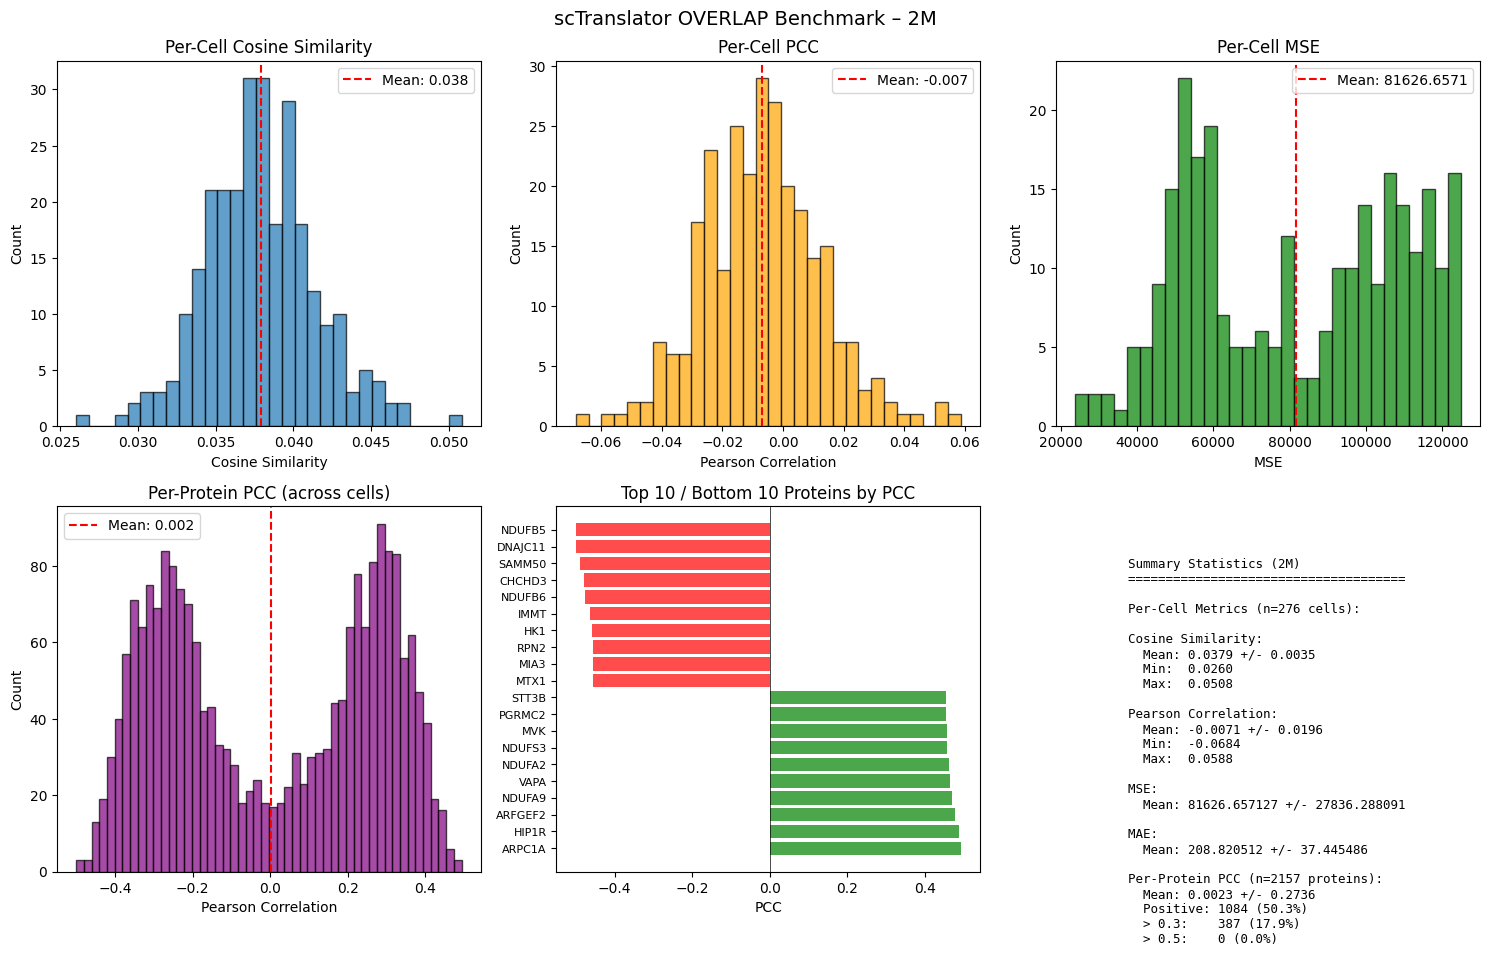

  Saved plot: benchmark_2M.png


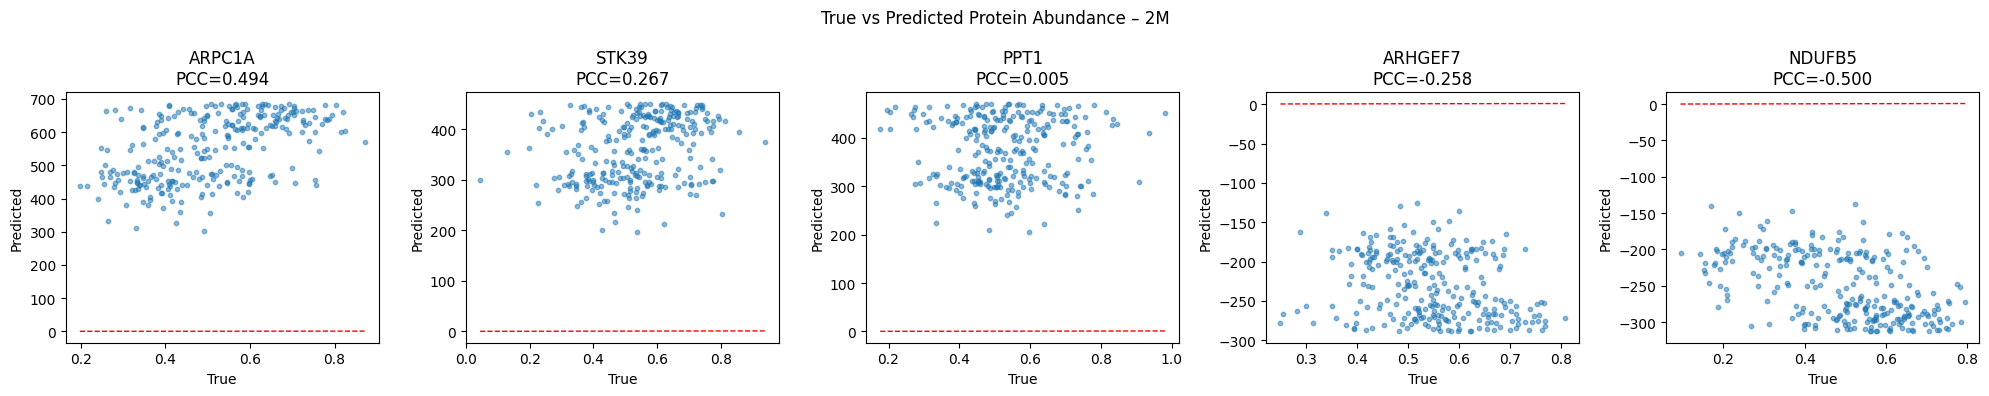

  Saved plot: scatter_2M.png

Benchmarking: 10K
Checkpoint: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_10K.pt

Loading model...
  Model loaded on cuda

Running inference...

Protein chunking: 2157 proteins -> 3 chunks of <=1000
  Chunk 1/3: proteins 0-1000 (1000 proteins)


  Chunk 1: 100%|██████████| 35/35 [00:09<00:00,  3.64it/s]


  Chunk 2/3: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 35/35 [00:09<00:00,  3.87it/s]


  Chunk 3/3: proteins 2000-2157 (157 proteins)


  Chunk 3: 100%|██████████| 35/35 [00:09<00:00,  3.89it/s]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\overlap_itraq\benchmark_results_OVERLAP\predictions_10K.npy

Computing metrics...

--- Results for 10K ---
Per-Cell Cosine: 0.9715 +/- 0.0099
Per-Cell PCC:    0.0060 +/- 0.0219
Per-Cell MSE:    0.025239 +/- 0.013055
Per-Cell MAE:    0.125622 +/- 0.034724
Per-Protein PCC: 0.2000 +/- 0.1694

Generating visualizations...


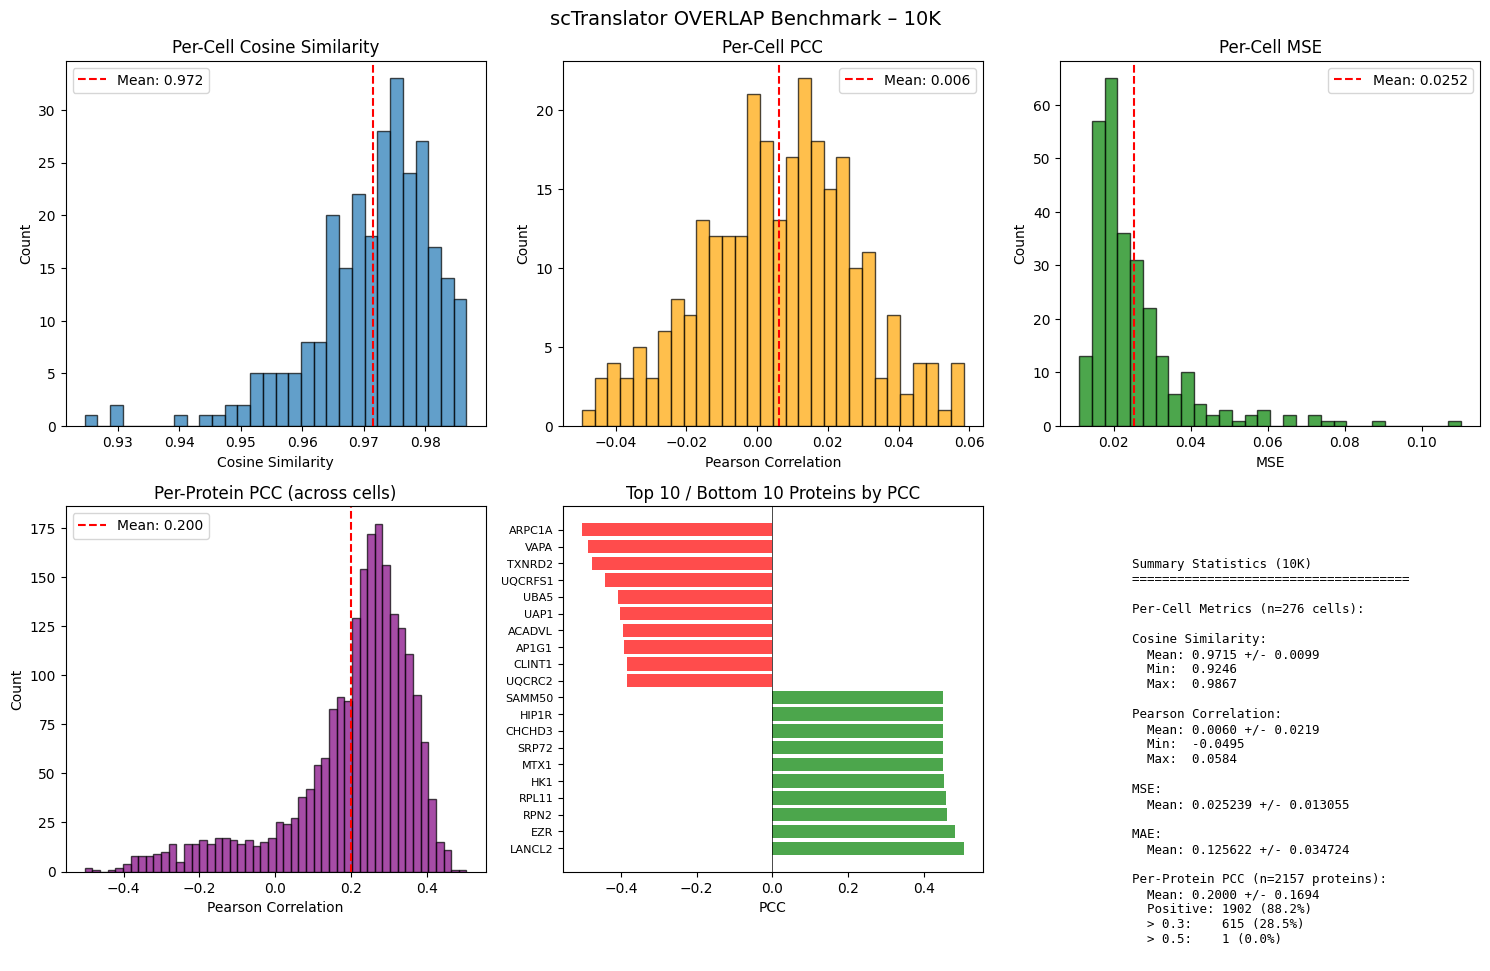

  Saved plot: benchmark_10K.png


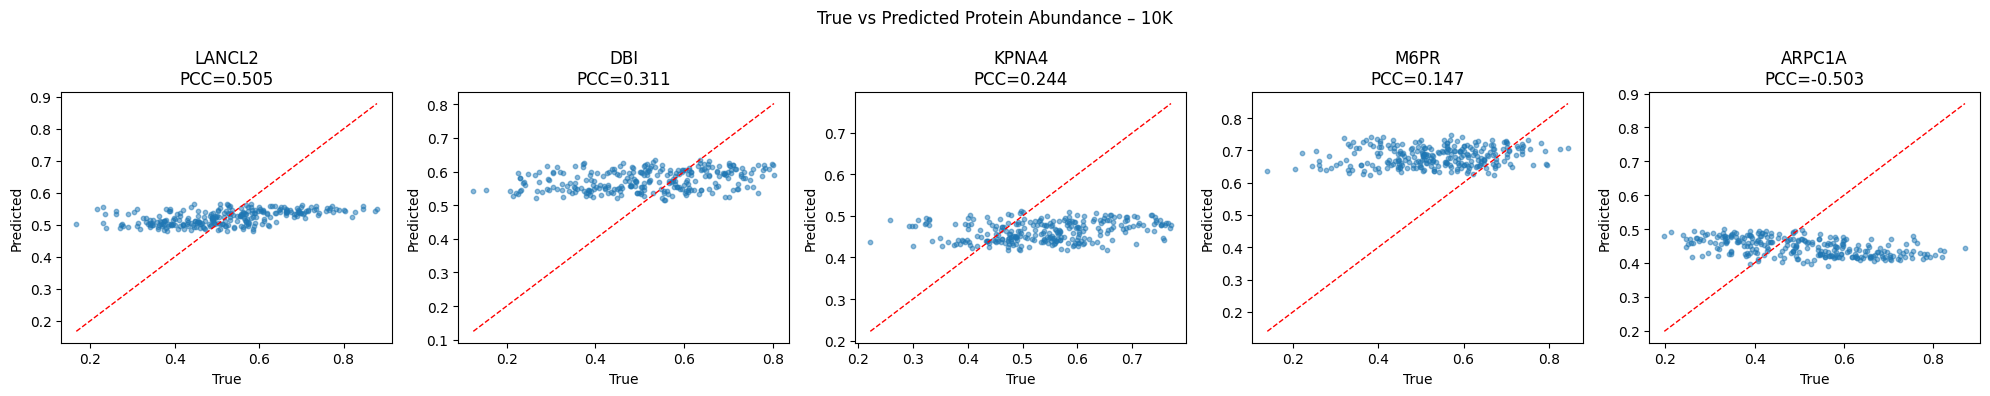

  Saved plot: scatter_10K.png

Benchmarking: 160K
Checkpoint: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_160K.pt

Loading model...
  Model loaded on cuda

Running inference...

Protein chunking: 2157 proteins -> 3 chunks of <=1000
  Chunk 1/3: proteins 0-1000 (1000 proteins)


  Chunk 1: 100%|██████████| 35/35 [00:09<00:00,  3.88it/s]


  Chunk 2/3: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 35/35 [00:08<00:00,  3.93it/s]


  Chunk 3/3: proteins 2000-2157 (157 proteins)


  Chunk 3: 100%|██████████| 35/35 [00:09<00:00,  3.84it/s]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\overlap_itraq\benchmark_results_OVERLAP\predictions_160K.npy

Computing metrics...

--- Results for 160K ---
Per-Cell Cosine: -0.5408 +/- 0.0077
Per-Cell PCC:    -0.0067 +/- 0.0371
Per-Cell MSE:    24765.654286 +/- 8881.919687
Per-Cell MAE:    145.180902 +/- 28.494810
Per-Protein PCC: -0.1027 +/- 0.2540

Generating visualizations...


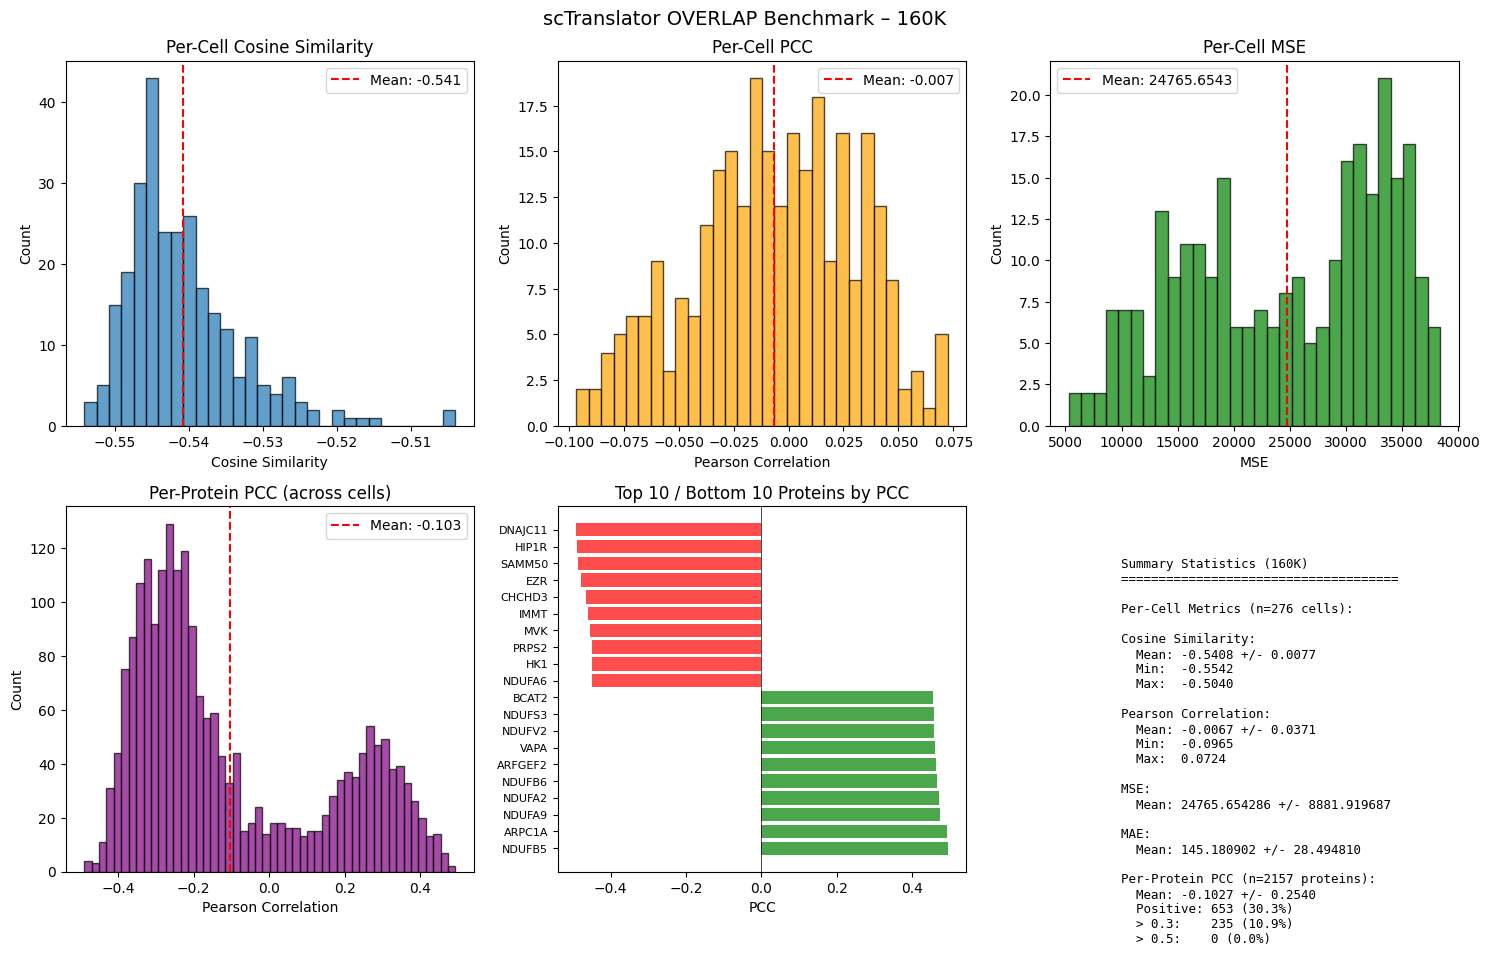

  Saved plot: benchmark_160K.png


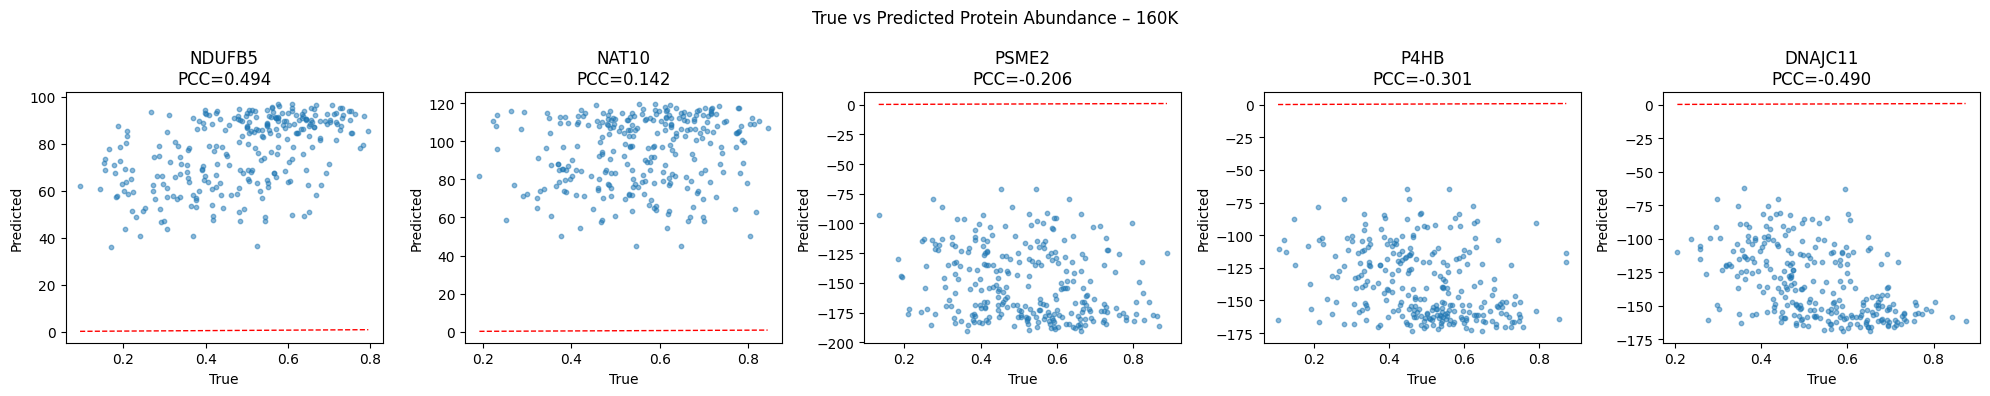

  Saved plot: scatter_160K.png


In [13]:
all_results = {}

for ckpt_name, ckpt_file in CONFIG['checkpoints'].items():
    if os.path.exists(ckpt_file):
        results = benchmark_checkpoint(ckpt_name, ckpt_file, data, CONFIG, device)
        all_results[ckpt_name] = results

        # Save individual results
        np.savez(
            os.path.join(CONFIG['output_dir'], f'results_{ckpt_name}.npz'),
            predictions=results['predictions'],
            cosine=results['metrics']['cosine'],
            pcc=results['metrics']['pcc'],
            mse=results['metrics']['mse'],
            mae=results['metrics']['mae'],
            protein_pccs=results['protein_pccs'],
        )

        # Clear GPU memory between checkpoints
        if device == 'cuda':
            torch.cuda.empty_cache()
    else:
        print(f"\nWarning: Checkpoint not found: {ckpt_file}")

### 10.4 Checkpoint Comparison Plot

### 10.5 Final Summary & Save

In [14]:
print("\n" + "=" * 60)
print("FINAL SUMMARY")
print("=" * 60)

ms = data['mapping_stats']

summary_lines = []
for ckpt_name, results in all_results.items():
    m  = results['metrics']
    pp = results['protein_pccs']
    line = (f"{ckpt_name}: Cosine={m['cosine'].mean():.4f}, "
            f"PCC={m['pcc'].mean():.4f}, MSE={m['mse'].mean():.6f}, "
            f"Protein-PCC={pp.mean():.4f}")
    print(line)
    summary_lines.append(line)

with open(os.path.join(CONFIG['output_dir'], 'summary.txt'), 'w') as f:
    f.write("scTranslator Benchmark Summary – OVERLAP ITRAQ Dataset\n")
    f.write("=" * 60 + "\n\n")
    f.write(f"Raw dataset: {data['n_cells']} samples x "
            f"{ms['prot_total']} proteins, {ms['rna_total']} RNA genes\n\n")

    f.write(f"Step 1: NaN Handling (threshold: >{ms['nan_threshold']*100:.0f}% NaN -> drop, "
            f"else fill with 1e-8)\n")
    f.write("-" * 50 + "\n")
    f.write(f"  RNA genes dropped (>{ms['nan_threshold']*100:.0f}% NaN): {ms['rna_dropped_nan']} / {ms['rna_total']} "
            f"({100*ms['rna_dropped_nan']/ms['rna_total']:.1f}%)\n")
    f.write(f"  RNA genes filled  (<=50% NaN):  {ms['rna_filled_nan']} / {ms['rna_total']} "
            f"({100*ms['rna_filled_nan']/ms['rna_total']:.1f}%)\n")
    f.write(f"  Proteins dropped  (>{ms['nan_threshold']*100:.0f}% NaN): {ms['prot_dropped_nan']} / {ms['prot_total']} "
            f"({100*ms['prot_dropped_nan']/ms['prot_total']:.1f}%)\n")
    f.write(f"  Proteins filled   (<=50% NaN):  {ms['prot_filled_nan']} / {ms['prot_total']} "
            f"({100*ms['prot_filled_nan']/ms['prot_total']:.1f}%)\n")
    f.write(f"  RNA genes remaining:          {ms['rna_after_nan']}\n")
    f.write(f"  Proteins remaining:           {ms['prot_after_nan']}\n\n")

    f.write("Step 2: scTranslator Vocabulary Mapping\n")
    f.write("-" * 50 + "\n")
    f.write(f"  RNA genes mapped:             {ms['rna_mapped']} / {ms['rna_after_nan']} "
            f"({100*ms['rna_mapped']/ms['rna_after_nan']:.1f}%)\n")
    f.write(f"  RNA genes unmapped:           {ms['rna_unmapped']}\n")
    f.write(f"  Proteins mapped:              {ms['prot_mapped']} / {ms['prot_after_nan']} "
            f"({100*ms['prot_mapped']/ms['prot_after_nan']:.1f}%)\n")
    f.write(f"  Proteins unmapped:            {ms['prot_unmapped']}\n")
    f.write(f"  Unmapped protein names:       {ms['prot_unmapped_names']}\n\n")

    f.write("Total Attrition\n")
    f.write("-" * 50 + "\n")
    f.write(f"  RNA:  {ms['rna_total']} -> {data['n_rna_genes']}  "
            f"(dropped {ms['rna_dropped_nan']} NaN + {ms['rna_unmapped']} unmapped, "
            f"{ms['rna_filled_nan']} cols NaN-filled)\n")
    f.write(f"  Prot: {ms['prot_total']} -> {data['n_proteins']}  "
            f"(dropped {ms['prot_dropped_nan']} NaN + {ms['prot_unmapped']} unmapped, "
            f"{ms['prot_filled_nan']} cols NaN-filled)\n\n")

    f.write(f"Final input: {data['n_cells']} samples x "
            f"{data['n_proteins']} proteins, {data['n_rna_genes']} RNA genes\n\n")
    f.write("Benchmark Results\n")
    f.write("-" * 50 + "\n")
    for line in summary_lines:
        f.write(line + "\n")

print(f"\nResults saved to: {CONFIG['output_dir']}")
print("Done!")


FINAL SUMMARY
2M: Cosine=0.0379, PCC=-0.0071, MSE=81626.657127, Protein-PCC=0.0023
10K: Cosine=0.9715, PCC=0.0060, MSE=0.025239, Protein-PCC=0.2000
160K: Cosine=-0.5408, PCC=-0.0067, MSE=24765.654286, Protein-PCC=-0.1027

Results saved to: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\overlap_itraq\benchmark_results_OVERLAP
Done!


---
## 12. All-Tissue Analysis

Extends the analysis to **every tissue** in the dataset.  
Because 12 tissues × 3 checkpoints generates a lot of numbers, we lean on:

| Visualisation | What it shows |
|---|---|
| **Annotated heatmaps** | Tissue × Checkpoint matrix for each metric — colour lets you spot patterns at a glance |
| **Sorted horizontal bar charts** | All tissues ranked by mean PCC; the three focus tissues are highlighted in colour |
| **Combined dot-plot** | Cosine & PCC side-by-side with error bars for every tissue |

Found 3 tissues:
  BREAST_2016                (77 samples)
  OVARY_2016                 (119 samples)
  STOMACH_2019               (80 samples)

ALL-TISSUE ANALYSIS  —  Averaged Per-Sample Metrics

  ── 2M ────────────────────────────────────────────────────────────────────────────────────────
  Tissue                        n          Cosine             PCC               MSE             MAE        Prot-PCC
  ------------------------- -----  --------------  --------------  ----------------  --------------  --------------
  Breast 2016                  77  +0.0385±0.0039  -0.0054±0.0217  63682.0747±15167.3865  +186.0622±22.1150  +0.0042±0.1044
  Ovary 2016                  119  +0.0373±0.0031  -0.0054±0.0206  109658.8468±9312.6333  +245.6760±10.4868  -0.0063±0.0635
  Stomach 2019                 80  +0.0381±0.0035  -0.0112±0.0148  57200.4355±15728.3484  +175.9028±24.5060  -0.0074±0.1808

  ── 10K ───────────────────────────────────────────────────────────────────────────────────────
  T

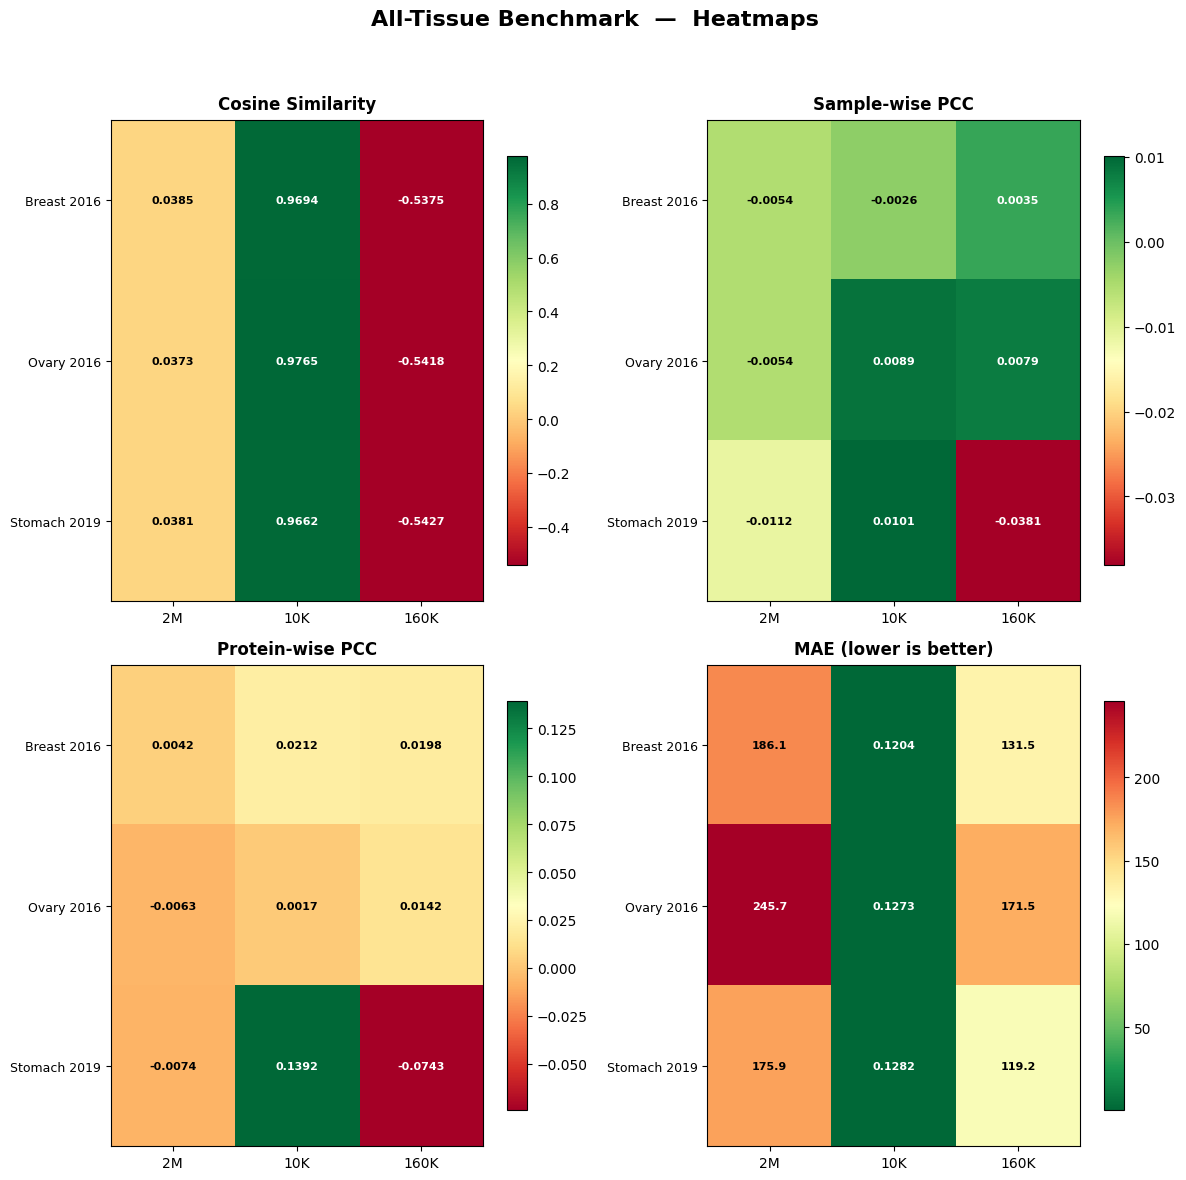

  Saved: all_tissue_heatmaps.png


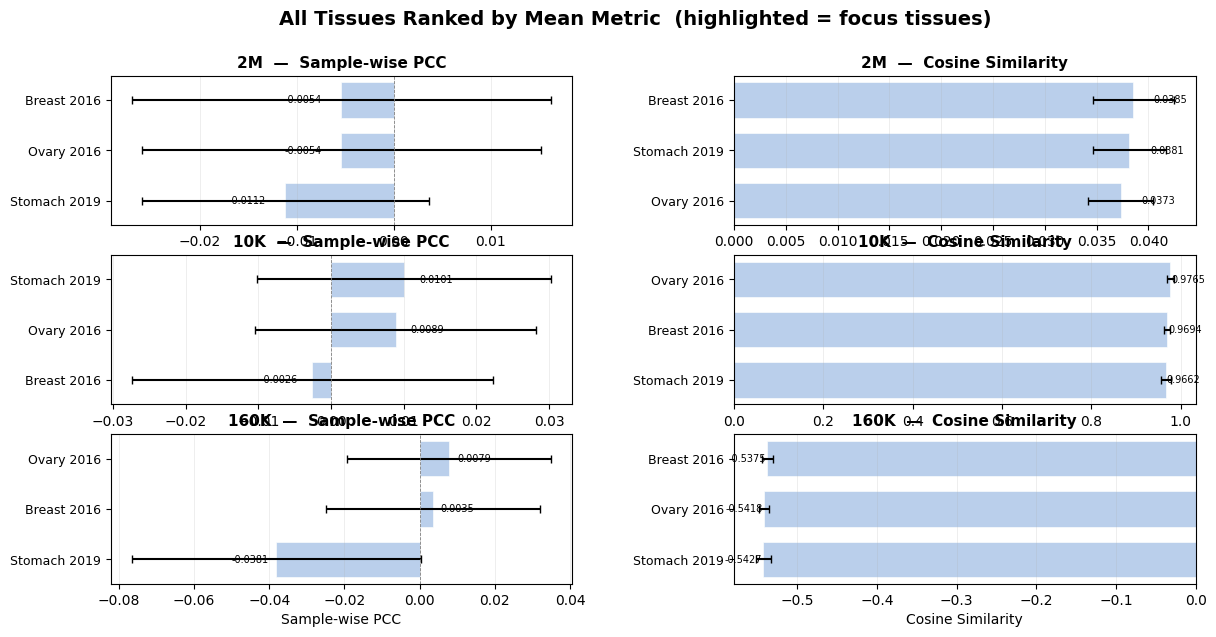

  Saved: all_tissue_ranked_bars.png


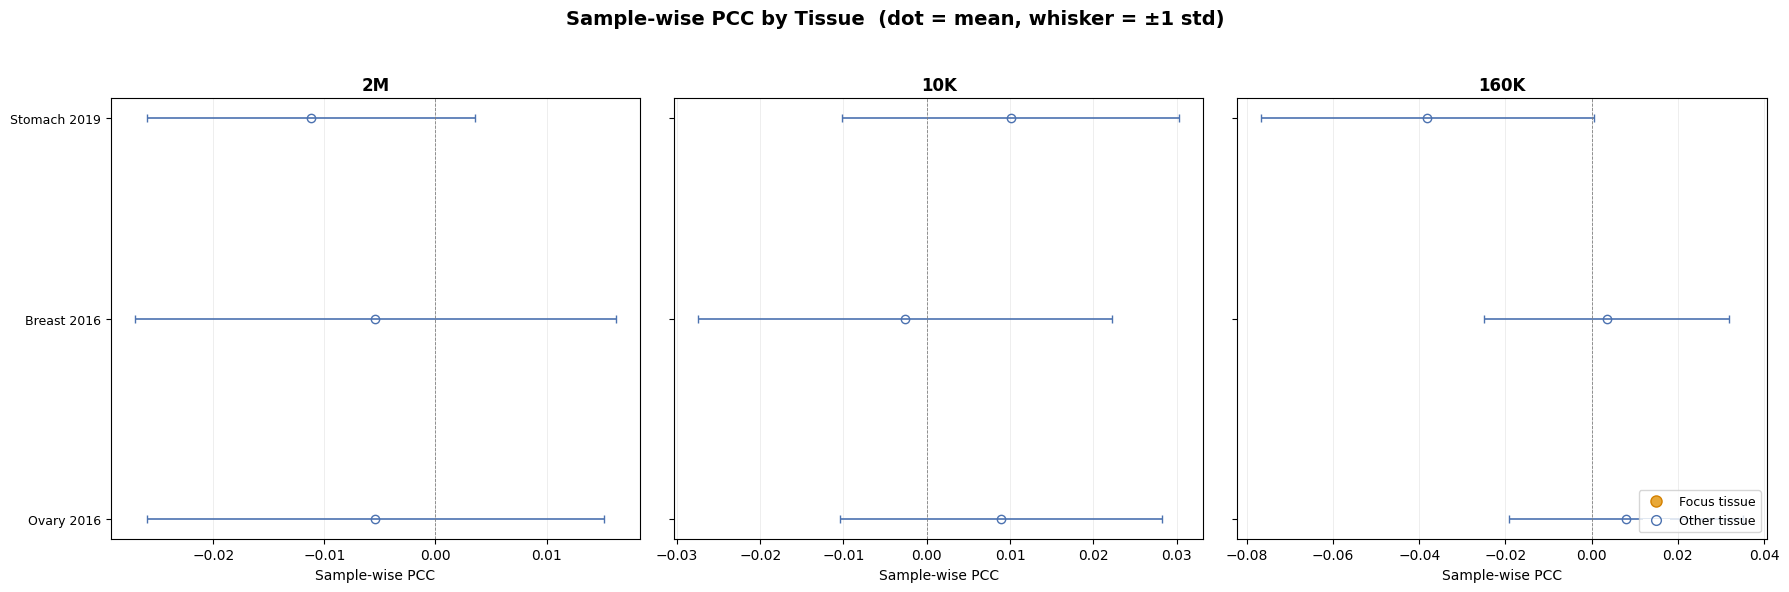

  Saved: all_tissue_dotplot.png


ValueError: The number of FixedLocator locations (6), usually from a call to set_ticks, does not match the number of labels (3).

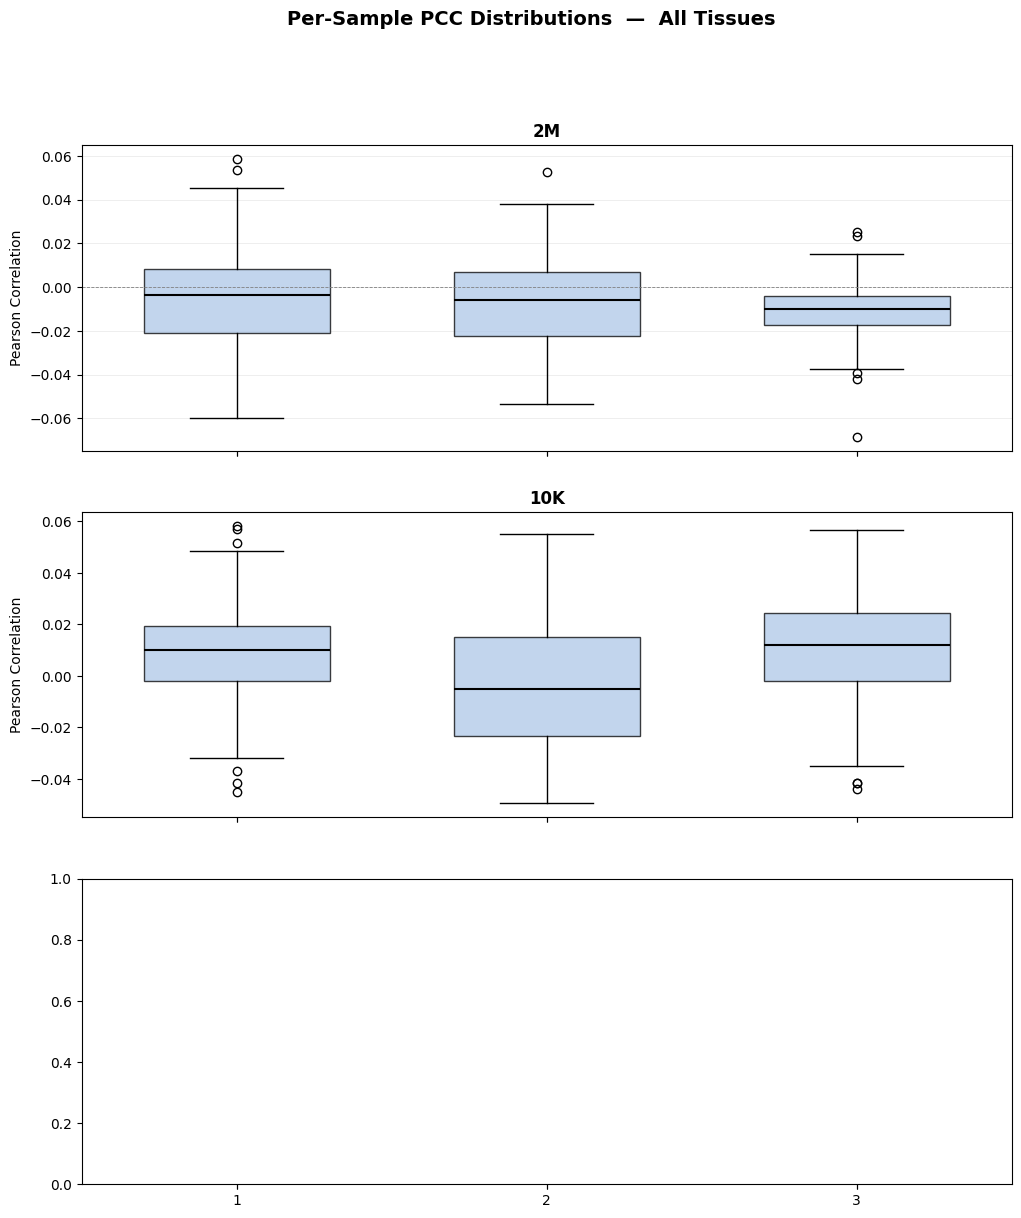

In [16]:
# ═══════════════════════════════════════════════════════════════════════════════
# 12. ALL-TISSUE ANALYSIS
# ═══════════════════════════════════════════════════════════════════════════════
import matplotlib.ticker as mticker

# ── Discover every tissue in the dataset ───────────────────────────────────
ALL_TISSUES = sorted(set(tissues))
print(f"Found {len(ALL_TISSUES)} tissues:")
for t in ALL_TISSUES:
    print(f"  {t:25s}  ({tissue_counts[t]} samples)")

# Friendly display names (auto-generate from IDs)
def _display(t):
    """Turn e.g. 'HEADNECK_2021' into 'Head & Neck 2021'."""
    return (t.replace('_', ' ')
             .replace('HEADNECK', 'Head & Neck')
             .replace('PANCREA', 'Pancreas ')
             .replace('PEDBRAIN', 'Ped. Brain')
             .title())

ALL_DISPLAY = {t: _display(t) for t in ALL_TISSUES}

# ── Compute tissue-level metrics for ALL tissues & all checkpoints ─────────
all_tissue_summary = {}  # {ckpt: {tissue: {...}}}

for ckpt_name, results in all_results.items():
    all_tissue_summary[ckpt_name] = {}
    metrics = results['metrics']

    for tissue in ALL_TISSUES:
        mask = tissues == tissue
        n = int(mask.sum())
        if n == 0:
            continue

        ts = {
            'n_samples':   n,
            'cosine_mean': float(metrics['cosine'][mask].mean()),
            'cosine_std':  float(metrics['cosine'][mask].std()),
            'pcc_mean':    float(metrics['pcc'][mask].mean()),
            'pcc_std':     float(metrics['pcc'][mask].std()),
            'mse_mean':    float(metrics['mse'][mask].mean()),
            'mse_std':     float(metrics['mse'][mask].std()),
            'mae_mean':    float(metrics['mae'][mask].mean()),
            'mae_std':     float(metrics['mae'][mask].std()),
        }

        # tissue-specific protein-wise PCC
        y_true_t = data['prot_values'][mask]
        y_pred_t = results['predictions'][mask]
        ppccs = compute_protein_wise_metrics(y_true_t, y_pred_t)
        ts['prot_pcc_mean'] = float(ppccs.mean())
        ts['prot_pcc_std']  = float(ppccs.std())

        all_tissue_summary[ckpt_name][tissue] = ts

checkpoints = list(all_results.keys())
n_ckpt = len(checkpoints)

# ── Print full table ──────────────────────────────────────────────────────
print("\n" + "=" * 110)
print("ALL-TISSUE ANALYSIS  —  Averaged Per-Sample Metrics")
print("=" * 110)
for ckpt in checkpoints:
    print(f"\n  ── {ckpt} {'─' * (90 - len(ckpt))}")
    print(f"  {'Tissue':25s} {'n':>5s}  {'Cosine':>14s}  {'PCC':>14s}  "
          f"{'MSE':>16s}  {'MAE':>14s}  {'Prot-PCC':>14s}")
    print(f"  {'-'*25} {'-'*5}  {'-'*14}  {'-'*14}  {'-'*16}  {'-'*14}  {'-'*14}")
    for tissue in ALL_TISSUES:
        ts = all_tissue_summary[ckpt].get(tissue)
        if ts is None:
            continue
        print(f"  {ALL_DISPLAY[tissue]:25s} {ts['n_samples']:5d}  "
              f"{ts['cosine_mean']:+.4f}±{ts['cosine_std']:.4f}  "
              f"{ts['pcc_mean']:+.4f}±{ts['pcc_std']:.4f}  "
              f"{ts['mse_mean']:10.4f}±{ts['mse_std']:.4f}  "
              f"{ts['mae_mean']:+.4f}±{ts['mae_std']:.4f}  "
              f"{ts['prot_pcc_mean']:+.4f}±{ts['prot_pcc_std']:.4f}")

# ═══════════════════════════════════════════════════════════════════════════
# FIGURE A — Annotated heatmaps for 4 key metrics
# ═══════════════════════════════════════════════════════════════════════════
metric_heatmap_defs = [
    ('cosine_mean', 'Cosine Similarity',    'RdYlGn'),
    ('pcc_mean',    'Sample-wise PCC',      'RdYlGn'),
    ('prot_pcc_mean', 'Protein-wise PCC',   'RdYlGn'),
    ('mae_mean',    'MAE (lower is better)', 'RdYlGn_r'),
]

fig, axes = plt.subplots(2, 2, figsize=(max(10, 4 * n_ckpt), 12))
fig.suptitle('All-Tissue Benchmark  —  Heatmaps', fontsize=16, fontweight='bold')

for ax, (m_key, title, cmap) in zip(axes.flat, metric_heatmap_defs):
    mat = np.full((len(ALL_TISSUES), n_ckpt), np.nan)
    for j, ckpt in enumerate(checkpoints):
        for i, tissue in enumerate(ALL_TISSUES):
            ts = all_tissue_summary[ckpt].get(tissue)
            if ts:
                mat[i, j] = ts[m_key]

    im = ax.imshow(mat, cmap=cmap, aspect='auto')
    ax.set_xticks(range(n_ckpt))
    ax.set_xticklabels(checkpoints, fontsize=10)
    ax.set_yticks(range(len(ALL_TISSUES)))
    ax.set_yticklabels([ALL_DISPLAY[t] for t in ALL_TISSUES], fontsize=9)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)

    # annotate cells
    for i in range(len(ALL_TISSUES)):
        for j in range(n_ckpt):
            val = mat[i, j]
            if np.isnan(val):
                continue
            vmin, vmax = np.nanmin(mat), np.nanmax(mat)
            mid = (vmin + vmax) / 2
            color = 'white' if abs(val - mid) > (vmax - vmin) * 0.3 else 'black'
            fmt = f'{val:.4f}' if abs(val) < 100 else f'{val:.1f}'
            ax.text(j, i, fmt, ha='center', va='center',
                    fontsize=8, fontweight='bold', color=color)

    plt.colorbar(im, ax=ax, shrink=0.85)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(os.path.join(CONFIG['output_dir'], 'all_tissue_heatmaps.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: all_tissue_heatmaps.png")

# ═══════════════════════════════════════════════════════════════════════════
# FIGURE B — Sorted horizontal bar charts (PCC & Cosine), focus highlighted
# ═══════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(n_ckpt, 2, figsize=(14, max(6, 2.2 * len(ALL_TISSUES))),
                         gridspec_kw={'wspace': 0.35})
if n_ckpt == 1:
    axes = axes[np.newaxis, :]
fig.suptitle('All Tissues Ranked by Mean Metric  (highlighted = focus tissues)',
             fontsize=14, fontweight='bold')

for row, ckpt in enumerate(checkpoints):
    for col, (m_key, label) in enumerate([('pcc_mean', 'Sample-wise PCC'),
                                           ('cosine_mean', 'Cosine Similarity')]):
        ax = axes[row, col]

        # Gather values and sort
        vals = []
        for t in ALL_TISSUES:
            ts = all_tissue_summary[ckpt].get(t)
            v  = ts[m_key] if ts else np.nan
            sd = ts.get(m_key.replace('mean', 'std'), 0) if ts else 0
            vals.append((t, v, sd))
        vals.sort(key=lambda x: x[1])

        y_pos = np.arange(len(vals))
        bar_vals  = [v for _, v, _ in vals]
        bar_errs  = [s for _, _, s in vals]
        bar_names = [ALL_DISPLAY[t] for t, _, _ in vals]
        bar_colors = ['#E8A838' if t in FOCUS_TISSUES else '#aec7e8' for t, _, _ in vals]

        ax.barh(y_pos, bar_vals, xerr=bar_errs, color=bar_colors,
                edgecolor='white', linewidth=0.5, alpha=0.85, capsize=3, height=0.7)
        ax.set_yticks(y_pos)
        ax.set_yticklabels(bar_names, fontsize=9)
        ax.set_xlabel(label)
        ax.set_title(f'{ckpt}  —  {label}', fontsize=11, fontweight='bold')
        ax.axvline(0, color='grey', linewidth=0.6, linestyle='--')
        ax.grid(axis='x', alpha=0.3, linewidth=0.5)

        # Annotate values on bars
        for yp, v in zip(y_pos, bar_vals):
            ax.text(v + 0.002 if v >= 0 else v - 0.002, yp,
                    f'{v:.4f}', va='center',
                    ha='left' if v >= 0 else 'right', fontsize=7)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join(CONFIG['output_dir'], 'all_tissue_ranked_bars.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: all_tissue_ranked_bars.png")

# ═══════════════════════════════════════════════════════════════════════════
# FIGURE C — Dot-plot: Cosine & PCC with error bars for every tissue
#             One row per checkpoint, two columns (Cosine, PCC)
# ═══════════════════════════════════════════════════════════════════════════
# Sort tissues by average PCC across all checkpoints for consistent ordering
avg_pcc_order = sorted(
    ALL_TISSUES,
    key=lambda t: np.mean([all_tissue_summary[c].get(t, {}).get('pcc_mean', -999)
                           for c in checkpoints]),
    reverse=True)

fig, axes = plt.subplots(1, n_ckpt, figsize=(6 * n_ckpt, max(6, 0.55 * len(ALL_TISSUES))),
                         sharey=True)
if n_ckpt == 1:
    axes = [axes]
fig.suptitle('Sample-wise PCC by Tissue  (dot = mean, whisker = ±1 std)',
             fontsize=14, fontweight='bold')

y_pos = np.arange(len(avg_pcc_order))

for ax, ckpt in zip(axes, checkpoints):
    means = []
    stds  = []
    colors = []
    for t in avg_pcc_order:
        ts = all_tissue_summary[ckpt].get(t, {})
        means.append(ts.get('pcc_mean', np.nan))
        stds.append(ts.get('pcc_std', 0))
        colors.append('#E8A838' if t in FOCUS_TISSUES else '#4C72B0')

    ax.errorbar(means, y_pos, xerr=stds, fmt='o', markersize=6,
                elinewidth=1.2, capsize=3, capthick=1,
                color='#4C72B0', markerfacecolor='none', zorder=2)
    # Overlay filled dots for focus tissues
    for i, t in enumerate(avg_pcc_order):
        if t in FOCUS_TISSUES:
            ax.plot(means[i], y_pos[i], 'o', markersize=8,
                    color='#E8A838', markeredgecolor='#d48000', zorder=3)

    ax.set_yticks(y_pos)
    ax.set_yticklabels([ALL_DISPLAY[t] for t in avg_pcc_order], fontsize=9)
    ax.set_xlabel('Sample-wise PCC')
    ax.set_title(ckpt, fontsize=12, fontweight='bold')
    ax.axvline(0, color='grey', linewidth=0.6, linestyle='--')
    ax.grid(axis='x', alpha=0.3, linewidth=0.5)

# Add a manual legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#E8A838',
           markeredgecolor='#d48000', markersize=8, label='Focus tissue'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='none',
           markeredgecolor='#4C72B0', markersize=7, label='Other tissue'),
]
axes[-1].legend(handles=legend_elements, fontsize=9, loc='lower right')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(os.path.join(CONFIG['output_dir'], 'all_tissue_dotplot.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: all_tissue_dotplot.png")

# ═══════════════════════════════════════════════════════════════════════════
# FIGURE D — Grouped box-plot: per-sample PCC distributions, all tissues
# ═══════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(n_ckpt, 1,
                         figsize=(max(12, 1.3 * len(ALL_TISSUES)), 4.5 * n_ckpt),
                         sharex=True)
if n_ckpt == 1:
    axes = [axes]
fig.suptitle('Per-Sample PCC Distributions  —  All Tissues',
             fontsize=14, fontweight='bold')

for ax, ckpt in zip(axes, checkpoints):
    box_data = []
    labels   = []
    face_colors = []
    for t in avg_pcc_order:
        mask = tissues == t
        box_data.append(all_results[ckpt]['metrics']['pcc'][mask])
        labels.append(ALL_DISPLAY[t])
        face_colors.append('#E8A838' if t in FOCUS_TISSUES else '#aec7e8')

    bp = ax.boxplot(box_data, patch_artist=True, widths=0.6,
                    medianprops=dict(color='black', linewidth=1.5))
    for patch, fc in zip(bp['boxes'], face_colors):
        patch.set_facecolor(fc)
        patch.set_alpha(0.75)

    ax.set_title(ckpt, fontsize=12, fontweight='bold')
    ax.set_ylabel('Pearson Correlation')
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
    ax.axhline(0, color='grey', linewidth=0.6, linestyle='--')
    ax.grid(axis='y', alpha=0.3, linewidth=0.5)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(os.path.join(CONFIG['output_dir'], 'all_tissue_boxplots.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: all_tissue_boxplots.png")

# ═══════════════════════════════════════════════════════════════════════════
# Save ALL-tissue results to CSV
# ═══════════════════════════════════════════════════════════════════════════
rows_all = []
for ckpt in checkpoints:
    for tissue in ALL_TISSUES:
        ts = all_tissue_summary[ckpt].get(tissue)
        if ts is None:
            continue
        rows_all.append({
            'Checkpoint':   ckpt,
            'Tissue':       ALL_DISPLAY[tissue],
            'Tissue_ID':    tissue,
            'N_samples':    ts['n_samples'],
            'Cosine_mean':  round(ts['cosine_mean'], 6),
            'Cosine_std':   round(ts['cosine_std'], 6),
            'PCC_mean':     round(ts['pcc_mean'], 6),
            'PCC_std':      round(ts['pcc_std'], 6),
            'MSE_mean':     round(ts['mse_mean'], 6),
            'MSE_std':      round(ts['mse_std'], 6),
            'MAE_mean':     round(ts['mae_mean'], 6),
            'MAE_std':      round(ts['mae_std'], 6),
            'ProtPCC_mean': round(ts['prot_pcc_mean'], 6),
            'ProtPCC_std':  round(ts['prot_pcc_std'], 6),
            'Focus':        tissue in FOCUS_TISSUES,
        })

all_tissue_df = pd.DataFrame(rows_all)
all_csv_path = os.path.join(CONFIG['output_dir'], 'all_tissue_metrics.csv')
all_tissue_df.to_csv(all_csv_path, index=False)

print(f"\nAll-tissue metrics saved to: {all_csv_path}")
print("\n" + all_tissue_df.to_string(index=False))


## 13. Per-Protein MSE Table (Excluding Focus Tissues)

Compute the **MSE of each protein averaged across samples**, after removing all
samples from `PANCREA2021`, `HEADNECK_2021`, and `RENAL_2019`.

In [17]:
# ═══════════════════════════════════════════════════════════════════════════════
# 13. PER-PROTEIN MSE TABLE  — excluding PANCREA2021, HEADNECK_2021, RENAL_2019
# ═══════════════════════════════════════════════════════════════════════════════

# Ensure tissue labels exist (safe to re-run)
def _get_tissue(name):
    parts = name.rsplit('_', 1)
    return parts[0] if len(parts) == 2 and parts[1].isdigit() else name

_EXCLUDE = {'PANCREA2021', 'HEADNECK_2021', 'RENAL_2019'}

cell_names  = data['cell_names']
_tissues    = np.array([_get_tissue(n) for n in cell_names])
keep_mask   = np.array([t not in _EXCLUDE for t in _tissues])

n_kept      = int(keep_mask.sum())
n_excluded  = len(keep_mask) - n_kept
print(f"Samples kept : {n_kept}  (excluded {n_excluded} from {_EXCLUDE})")

prot_genes  = data['prot_genes']
y_true_filt = data['prot_values'][keep_mask]          # (n_kept, n_proteins)

# ── Build a DataFrame: one row per protein, one MSE column per checkpoint ──
mse_dict = {'Protein': prot_genes}

for ckpt_name, results in all_results.items():
    y_pred_filt = results['predictions'][keep_mask]   # (n_kept, n_proteins)
    # Per-protein MSE = mean over kept samples of (true - pred)^2
    per_protein_mse = np.mean((y_true_filt - y_pred_filt) ** 2, axis=0)
    mse_dict[f'MSE_{ckpt_name}'] = np.round(per_protein_mse, 8)

protein_mse_df = pd.DataFrame(mse_dict)

mse_cols = [c for c in protein_mse_df.columns if c.startswith('MSE_')]
protein_mse_df = protein_mse_df.sort_values(mse_cols[0], ascending=True).reset_index(drop=True)

# ── Save to CSV ───────────────────────────────────────────────────────────
csv_path = os.path.join(CONFIG['output_dir'], 'per_protein_mse_excl_focus.csv')
protein_mse_df.to_csv(csv_path, index=False)
print(f"Saved: {csv_path}")

# ── Display the full table ────────────────────────────────────────────────
pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', '{:.6f}'.format)
print(f"\nPer-Protein MSE  ({n_kept} samples, 3 focus tissues excluded)")
print(f"{'=' * 80}")
print(protein_mse_df.to_string(index=False))

# ── Quick summary stats ──────────────────────────────────────────────────
print(f"\n{'=' * 80}")
print("Summary (across all {0} proteins):".format(len(prot_genes)))
for col in mse_cols:
    vals = protein_mse_df[col]
    print(f"  {col:20s}  mean={vals.mean():.6f}  median={vals.median():.6f}  "
          f"min={vals.min():.6f}  max={vals.max():.6f}")

pd.reset_option('display.max_rows')
pd.reset_option('display.float_format')

Samples kept : 276  (excluded 0 from {'HEADNECK_2021', 'PANCREA2021', 'RENAL_2019'})
Saved: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\overlap_itraq\benchmark_results_OVERLAP\per_protein_mse_excl_focus.csv

Per-Protein MSE  (276 samples, 3 focus tissues excluded)
  Protein         MSE_2M  MSE_10K      MSE_160K
    PTCD3       0.182655 0.052749  42040.761719
     ILF3       0.486974 0.014535  18801.326172
    GOSR1       0.565702 0.031262  24674.988281
    DDX17       0.601691 0.015246  42098.179688
   TARDBP       0.608985 0.013872  18797.240234
    SLIRP       0.670823 0.030884  24693.552734
    PDIA3       2.035483 0.064448  25942.464844
      SPR       2.280092 0.022288  31969.558594
     QDPR       2.301336 0.017545  20814.501953
     DLAT       2.379350 0.020081  20786.109375
   CKMT1A       2.629992 0.048183  36966.257812
   PIK3R4       2.655937 0.011431  36940.882812
      CCS       2.768831 0.014606  25910.900391
    SAR1B       2.811544 0.037595

---
## 14. Per-Sample & Per-Protein R² Analysis

Compute the **coefficient of determination (R²)** in two directions:

1. **Per-sample R²** — for each sample, compute R² across all proteins between predicted and ground-truth abundance.
2. **Per-protein R²** — for each protein, compute R² across all samples between predicted and ground-truth abundance.

Histograms visualise the distribution of R² values for each checkpoint.

── 2M ──
  Per-sample  R²:  mean=-11589238.5960  std=8467369.1499  median=-9042964.5000  min=-52648084.0000  max=-2061155.5000
  Per-protein R²:  mean=-5135540.3939  std=8873971.4514  median=-1545539.7500  min=-166288096.0000  max=-12.2906

── 10K ──
  Per-sample  R²:  mean=-2.3680  std=2.8423  median=-1.3581  min=-17.8155  max=-0.3007
  Per-protein R²:  mean=-0.4821  std=0.8360  median=-0.1898  min=-9.8888  max=0.1376

── 160K ──
  Per-sample  R²:  mean=-3517617.2329  std=2601984.9347  median=-2793376.2500  min=-16400608.0000  max=-471237.7812
  Per-protein R²:  mean=-1556195.9600  std=1212436.5622  median=-1398633.3750  min=-11591782.0000  max=-573.4509



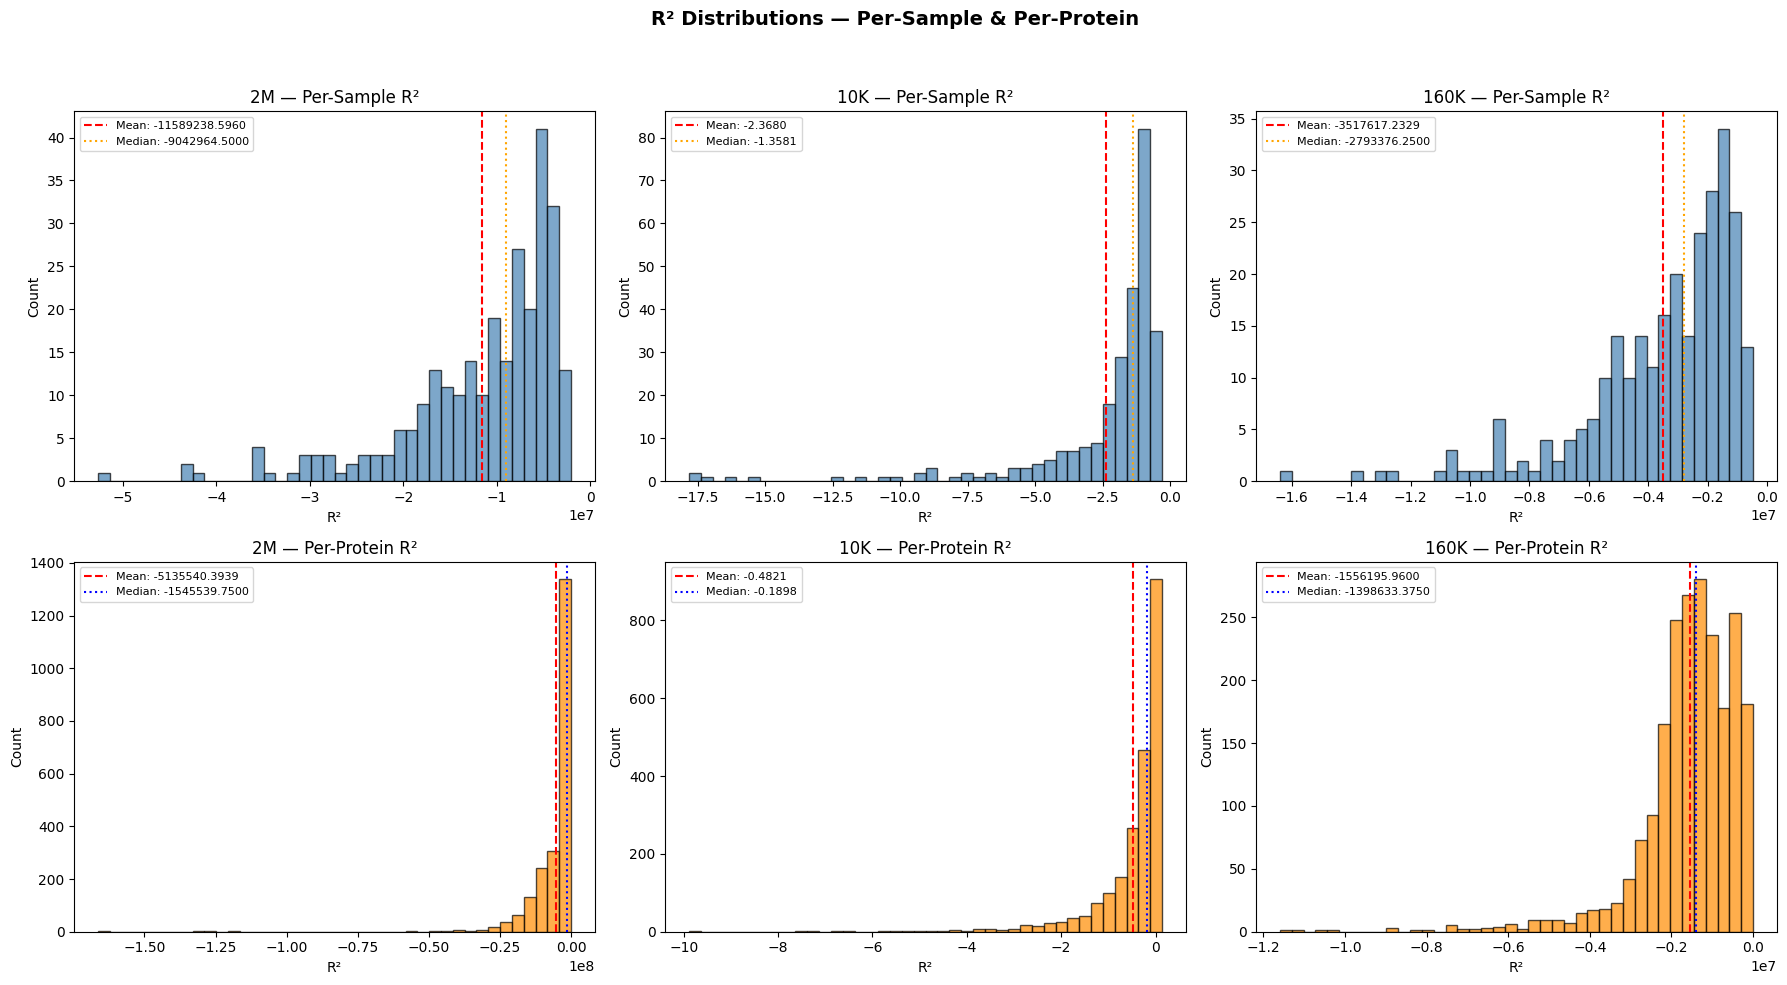

Saved: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\overlap_itraq\benchmark_results_OVERLAP\r2_histograms.png


In [18]:
from sklearn.metrics import r2_score

# ── Helper functions ──────────────────────────────────────────────────────────

def compute_per_sample_r2(y_true, y_pred):
    """R² for each sample (row) across all proteins."""
    n_samples = y_true.shape[0]
    r2_vals = np.empty(n_samples)
    for i in range(n_samples):
        ss_res = np.sum((y_true[i] - y_pred[i]) ** 2)
        ss_tot = np.sum((y_true[i] - np.mean(y_true[i])) ** 2)
        r2_vals[i] = 1.0 - ss_res / ss_tot if ss_tot > 0 else 0.0
    return r2_vals


def compute_per_protein_r2(y_true, y_pred):
    """R² for each protein (column) across all samples."""
    n_proteins = y_true.shape[1]
    r2_vals = np.empty(n_proteins)
    for j in range(n_proteins):
        ss_res = np.sum((y_true[:, j] - y_pred[:, j]) ** 2)
        ss_tot = np.sum((y_true[:, j] - np.mean(y_true[:, j])) ** 2)
        r2_vals[j] = 1.0 - ss_res / ss_tot if ss_tot > 0 else 0.0
    return r2_vals


# ── Compute R² for every checkpoint ──────────────────────────────────────────
y_true = data['prot_values']
r2_results = {}

for ckpt_name, results in all_results.items():
    y_pred = results['predictions']
    sample_r2  = compute_per_sample_r2(y_true, y_pred)
    protein_r2 = compute_per_protein_r2(y_true, y_pred)
    r2_results[ckpt_name] = {
        'sample_r2':  sample_r2,
        'protein_r2': protein_r2,
    }
    print(f"── {ckpt_name} ──")
    print(f"  Per-sample  R²:  mean={sample_r2.mean():.4f}  std={sample_r2.std():.4f}  "
          f"median={np.median(sample_r2):.4f}  min={sample_r2.min():.4f}  max={sample_r2.max():.4f}")
    print(f"  Per-protein R²:  mean={protein_r2.mean():.4f}  std={protein_r2.std():.4f}  "
          f"median={np.median(protein_r2):.4f}  min={protein_r2.min():.4f}  max={protein_r2.max():.4f}")
    print()

# ── Histograms: per-sample R² and per-protein R² ─────────────────────────────
checkpoints = list(all_results.keys())
n_ckpt = len(checkpoints)

fig, axes = plt.subplots(2, n_ckpt, figsize=(6 * n_ckpt, 10))
if n_ckpt == 1:                       # ensure 2D indexing even with 1 checkpoint
    axes = axes.reshape(2, 1)

for j, ckpt in enumerate(checkpoints):
    sr2 = r2_results[ckpt]['sample_r2']
    pr2 = r2_results[ckpt]['protein_r2']

    # Row 0 — per-sample R²
    ax = axes[0, j]
    ax.hist(sr2, bins=40, edgecolor='black', alpha=0.7, color='steelblue')
    ax.axvline(sr2.mean(), color='red', linestyle='--',
               label=f'Mean: {sr2.mean():.4f}')
    ax.axvline(np.median(sr2), color='orange', linestyle=':',
               label=f'Median: {np.median(sr2):.4f}')
    ax.set_xlabel('R²')
    ax.set_ylabel('Count')
    ax.set_title(f'{ckpt} — Per-Sample R²')
    ax.legend(fontsize=8)

    # Row 1 — per-protein R²
    ax = axes[1, j]
    ax.hist(pr2, bins=40, edgecolor='black', alpha=0.7, color='darkorange')
    ax.axvline(pr2.mean(), color='red', linestyle='--',
               label=f'Mean: {pr2.mean():.4f}')
    ax.axvline(np.median(pr2), color='blue', linestyle=':',
               label=f'Median: {np.median(pr2):.4f}')
    ax.set_xlabel('R²')
    ax.set_ylabel('Count')
    ax.set_title(f'{ckpt} — Per-Protein R²')
    ax.legend(fontsize=8)

fig.suptitle('R² Distributions — Per-Sample & Per-Protein', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_path = os.path.join(CONFIG['output_dir'], 'r2_histograms.png')
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Saved: {save_path}")

TISSUE-LEVEL  R²  (per-sample R² averaged by tissue)

  ── 2M ────────────────────────────────────────────────────────────────────────────────────────
  Tissue                        n     R² mean      R² std   R² median      R² min      R² max
  ------------------------- -----  ----------  ----------  ----------  ----------  ----------
  Breast 2016                  77  -7007911.2013  2474245.0590  -6433482.0000  -14092393.0000  -3538667.0000
  Ovary 2016                  119  -18556162.3529  8433560.6705  -16799520.0000  -52648084.0000  -7843964.0000
  Stomach 2019                 80  -5635467.1250  2795085.1043  -5157086.5000  -16689557.0000  -2061155.5000

  ── 10K ───────────────────────────────────────────────────────────────────────────────────────
  Tissue                        n     R² mean      R² std   R² median      R² min      R² max
  ------------------------- -----  ----------  ----------  ----------  ----------  ----------
  Breast 2016                  77     -1.5855 

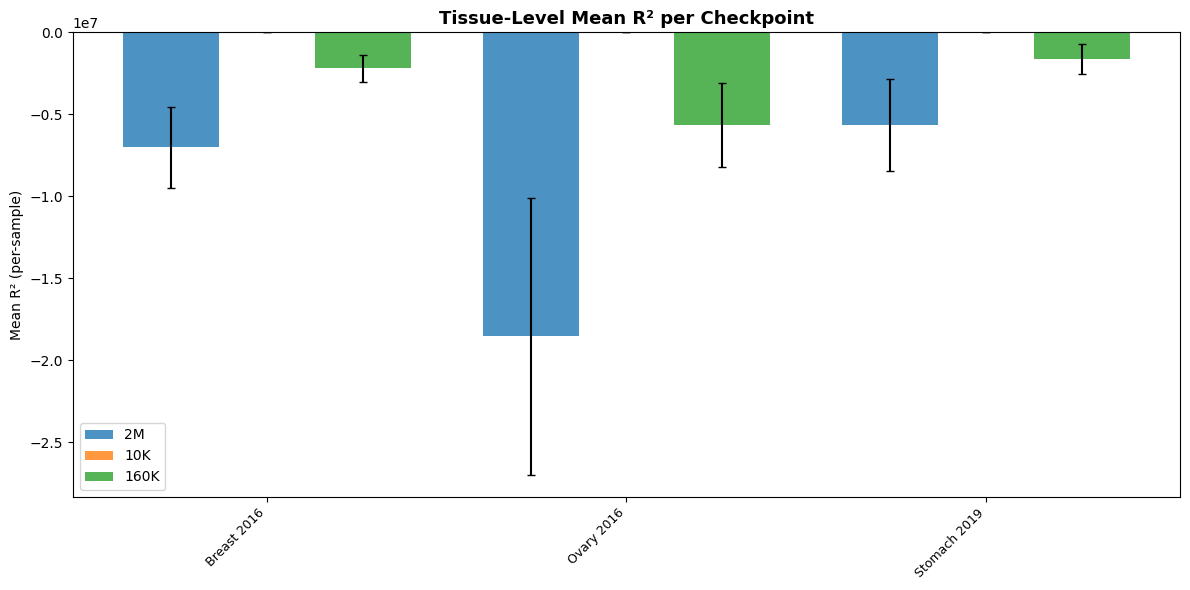

Saved: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\overlap_itraq\benchmark_results_OVERLAP\tissue_r2_barplot.png


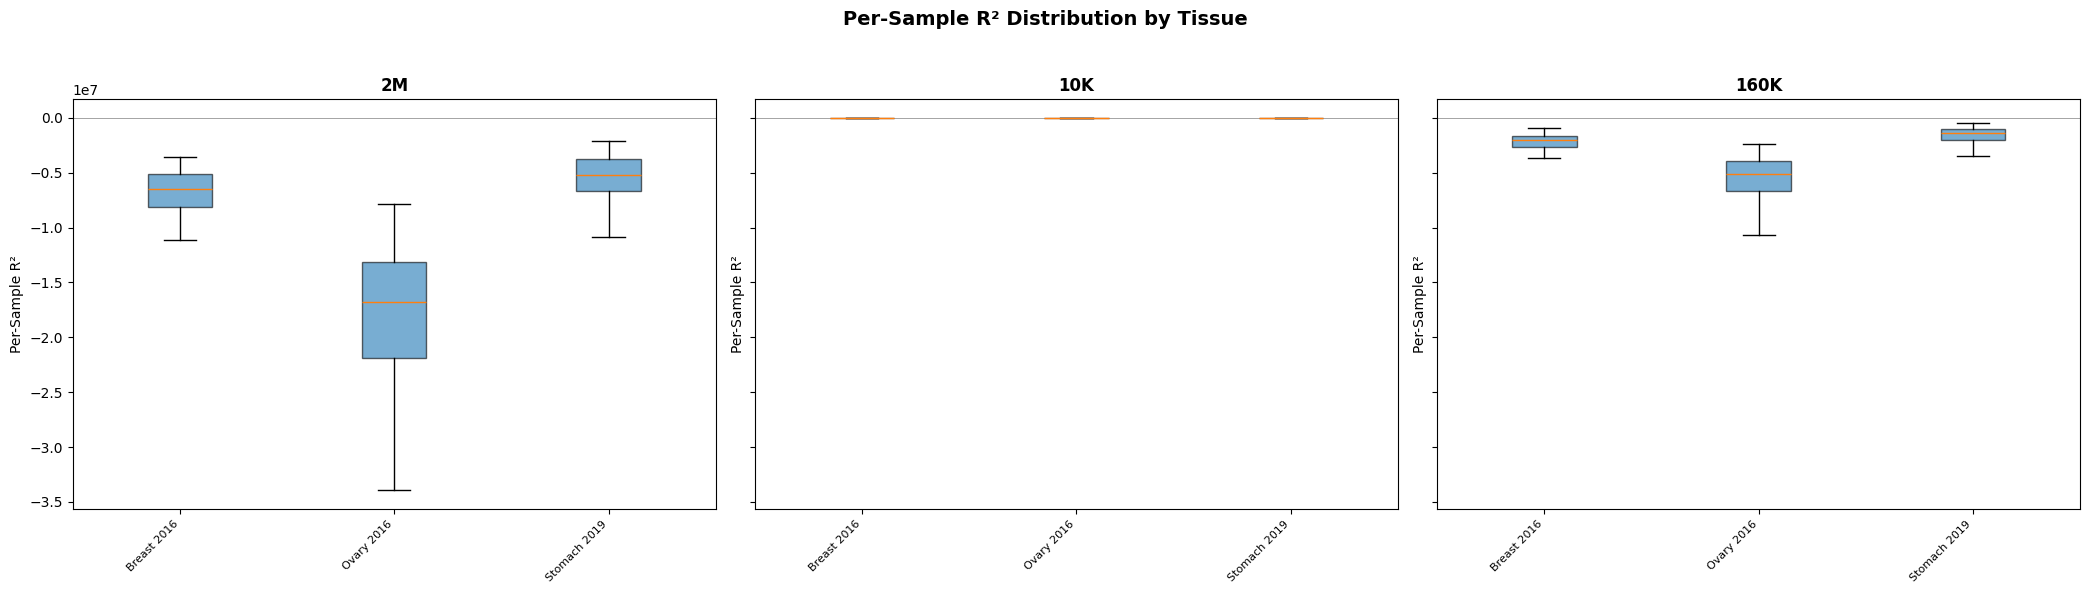

Saved: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\overlap_itraq\benchmark_results_OVERLAP\tissue_r2_boxplots.png


In [19]:
from collections import Counter

# ── Re-derive tissue labels (safe to re-run) ─────────────────────────────────
def _tissue_from_name(name):
    parts = name.rsplit('_', 1)
    return parts[0] if len(parts) == 2 and parts[1].isdigit() else name

cell_names = data['cell_names']
tissues_arr = np.array([_tissue_from_name(n) for n in cell_names])
ALL_TISSUES_SORTED = sorted(set(tissues_arr))

# ── Pretty display names (strip trailing year for readability) ────────────────
def _display(t):
    """PANCREA2021 -> Pancrea2021, HEADNECK_2021 -> Headneck 2021, etc."""
    return t.replace('_', ' ').title()

# ── Compute tissue-level R² for each checkpoint ──────────────────────────────
tissue_r2_records = []  # flat list for DataFrame

for ckpt in checkpoints:
    sr2 = r2_results[ckpt]['sample_r2']
    for tissue in ALL_TISSUES_SORTED:
        mask = tissues_arr == tissue
        n = int(mask.sum())
        if n == 0:
            continue
        r2_tissue = sr2[mask]
        tissue_r2_records.append({
            'Checkpoint': ckpt,
            'Tissue': tissue,
            'Tissue_Display': _display(tissue),
            'N_samples': n,
            'R2_mean': r2_tissue.mean(),
            'R2_std': r2_tissue.std(),
            'R2_median': np.median(r2_tissue),
            'R2_min': r2_tissue.min(),
            'R2_max': r2_tissue.max(),
        })

tissue_r2_df = pd.DataFrame(tissue_r2_records)

# ── Print summary table ──────────────────────────────────────────────────────
print("=" * 110)
print("TISSUE-LEVEL  R²  (per-sample R² averaged by tissue)")
print("=" * 110)
for ckpt in checkpoints:
    sub = tissue_r2_df[tissue_r2_df['Checkpoint'] == ckpt]
    print(f"\n  ── {ckpt} {'─' * (90 - len(ckpt))}")
    print(f"  {'Tissue':<25s} {'n':>5s}  {'R² mean':>10s}  {'R² std':>10s}  {'R² median':>10s}  {'R² min':>10s}  {'R² max':>10s}")
    print(f"  {'-'*25} {'-'*5}  {'-'*10}  {'-'*10}  {'-'*10}  {'-'*10}  {'-'*10}")
    for _, row in sub.iterrows():
        print(f"  {row['Tissue_Display']:<25s} {row['N_samples']:5d}  "
              f"{row['R2_mean']:+10.4f}  {row['R2_std']:10.4f}  "
              f"{row['R2_median']:+10.4f}  {row['R2_min']:+10.4f}  {row['R2_max']:+10.4f}")

# ── Save to CSV ──────────────────────────────────────────────────────────────
csv_path = os.path.join(CONFIG['output_dir'], 'tissue_level_r2.csv')
tissue_r2_df.to_csv(csv_path, index=False)
print(f"\nSaved: {csv_path}")

# ═══════════════════════════════════════════════════════════════════════════════
# Grouped bar chart — tissue-level mean R² per checkpoint
# ═══════════════════════════════════════════════════════════════════════════════
tissue_labels = [_display(t) for t in ALL_TISSUES_SORTED]
x = np.arange(len(ALL_TISSUES_SORTED))
bar_width = 0.8 / n_ckpt

fig, ax = plt.subplots(figsize=(max(12, len(ALL_TISSUES_SORTED) * 1.2), 6))

for j, ckpt in enumerate(checkpoints):
    means = []
    stds  = []
    for tissue in ALL_TISSUES_SORTED:
        row = tissue_r2_df[(tissue_r2_df['Checkpoint'] == ckpt) &
                           (tissue_r2_df['Tissue'] == tissue)]
        means.append(row['R2_mean'].values[0] if len(row) else 0.0)
        stds.append(row['R2_std'].values[0] if len(row) else 0.0)
    offset = (j - n_ckpt / 2 + 0.5) * bar_width
    ax.bar(x + offset, means, bar_width, yerr=stds, capsize=3,
           label=ckpt, alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(tissue_labels, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Mean R² (per-sample)')
ax.set_title('Tissue-Level Mean R² per Checkpoint', fontsize=13, fontweight='bold')
ax.legend()
ax.axhline(0, color='grey', linewidth=0.5, linestyle='-')
plt.tight_layout()
save_path = os.path.join(CONFIG['output_dir'], 'tissue_r2_barplot.png')
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Saved: {save_path}")

# ═══════════════════════════════════════════════════════════════════════════════
# Box-plot of per-sample R² by tissue (one subplot per checkpoint)
# ═══════════════════════════════════════════════════════════════════════════════
fig, axes_bp = plt.subplots(1, n_ckpt, figsize=(7 * n_ckpt, 6), sharey=True)
if n_ckpt == 1:
    axes_bp = [axes_bp]

for j, ckpt in enumerate(checkpoints):
    sr2 = r2_results[ckpt]['sample_r2']
    box_data = []
    box_labels = []
    for tissue in ALL_TISSUES_SORTED:
        mask = tissues_arr == tissue
        box_data.append(sr2[mask])
        box_labels.append(_display(tissue))

    ax = axes_bp[j]
    bp = ax.boxplot(box_data, patch_artist=True, showfliers=False)
    for patch in bp['boxes']:
        patch.set_alpha(0.6)
    ax.set_xticklabels(box_labels, rotation=45, ha='right', fontsize=8)
    ax.set_ylabel('Per-Sample R²')
    ax.set_title(f'{ckpt}', fontsize=12, fontweight='bold')
    ax.axhline(0, color='grey', linewidth=0.5, linestyle='-')

fig.suptitle('Per-Sample R² Distribution by Tissue', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_path = os.path.join(CONFIG['output_dir'], 'tissue_r2_boxplots.png')
plt.savefig(save_path, dpi=150)
plt.show()
print(f"Saved: {save_path}")